# Predicting Monthly Electricity Consumption

## Project Overview
This project explores energy consumption patterns across hundreds of properties in Ontario. We will build a machine learning model to predict monthly electricity consumption (usage) for buildings using only readings from Electric – Grid meters (measured in kWh).

## Objectives
1. Clean and prepare the dataset for analysis
2. Perform exploratory data analysis to understand patterns
3. Engineer features for better model performance
4. Build and compare multiple machine learning models
5. Evaluate model performance and interpret results

## 1. Import Required Libraries

We'll use pandas for data manipulation, numpy for numerical operations, matplotlib and seaborn for visualization, and sklearn for machine learning.

In [1]:
# Data manipulation and analysis libraries
import pandas as pd
import numpy as np

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats  # For statistical plots (Q-Q plot)

# Machine learning libraries from sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Set visualization style for better-looking plots
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
# Enable inline plotting for Jupyter notebooks
%matplotlib inline

# Set random seed for reproducibility
np.random.seed(42)

print("Libraries imported successfully!")
print("Matplotlib.pyplot is ready for creating comprehensive data visualizations!")


Libraries imported successfully!
Matplotlib.pyplot is ready for creating comprehensive data visualizations!


## 2. Load the Datasets

We have four CSV files:
- **meter_entries.csv**: Monthly meter readings (our main target data)
- **meters.csv**: Information about meters installed at each property
- **properties.csv**: Property characteristics
- **uses.csv**: Floor area allocation by use type

In [2]:
# Load all datasets into pandas DataFrames
# We'll use relative paths assuming the notebook is in the project root

print("Loading datasets...")

# Load meter entries - contains monthly consumption readings
meter_entries = pd.read_csv('datasets/meter_entries.csv')
print(f"Meter entries shape: {meter_entries.shape}")

# Load meters information - contains meter metadata
meters = pd.read_csv('datasets/meters.csv')
print(f"Meters shape: {meters.shape}")

# Load properties information - contains property characteristics
properties = pd.read_csv('datasets/properties.csv')
print(f"Properties shape: {properties.shape}")

# Load uses information - contains floor area by use type
uses = pd.read_csv('datasets/uses.csv')
print(f"Uses shape: {uses.shape}")

print("\nAll datasets loaded successfully!")

Loading datasets...
Meter entries shape: (26222, 11)
Meters shape: (2585, 8)
Properties shape: (1760, 8)
Uses shape: (1760, 7)

All datasets loaded successfully!


## 3. Initial Data Exploration

Let's examine the structure and content of each dataset to understand what we're working with.

DATASET 1: METER ENTRIES
Shape: 26222 rows × 11 columns

Columns: ['Property Name', 'Portfolio Manager ID', 'Portfolio Manager Meter ID', 'Meter Name', 'Meter Type', 'Meter Consumption ID', 'Start Date', 'End Date', 'Usage/Quantity', 'Usage Units', 'Cost ($)']

--------------------------------------------------------------------------------
First 5 rows:
--------------------------------------------------------------------------------
         Property Name  Portfolio Manager ID  Portfolio Manager Meter ID  \
0  #13 Police Division              35000258                   189947941   
1  #13 Police Division              35000258                   189947941   
2  #13 Police Division              35000258                   189947941   
3  #13 Police Division              35000258                   189947941   
4  #13 Police Division              35000258                   189947941   

                          Meter Name       Meter Type  Meter Consumption ID  \
0  AUTO_#13 Police Divisio

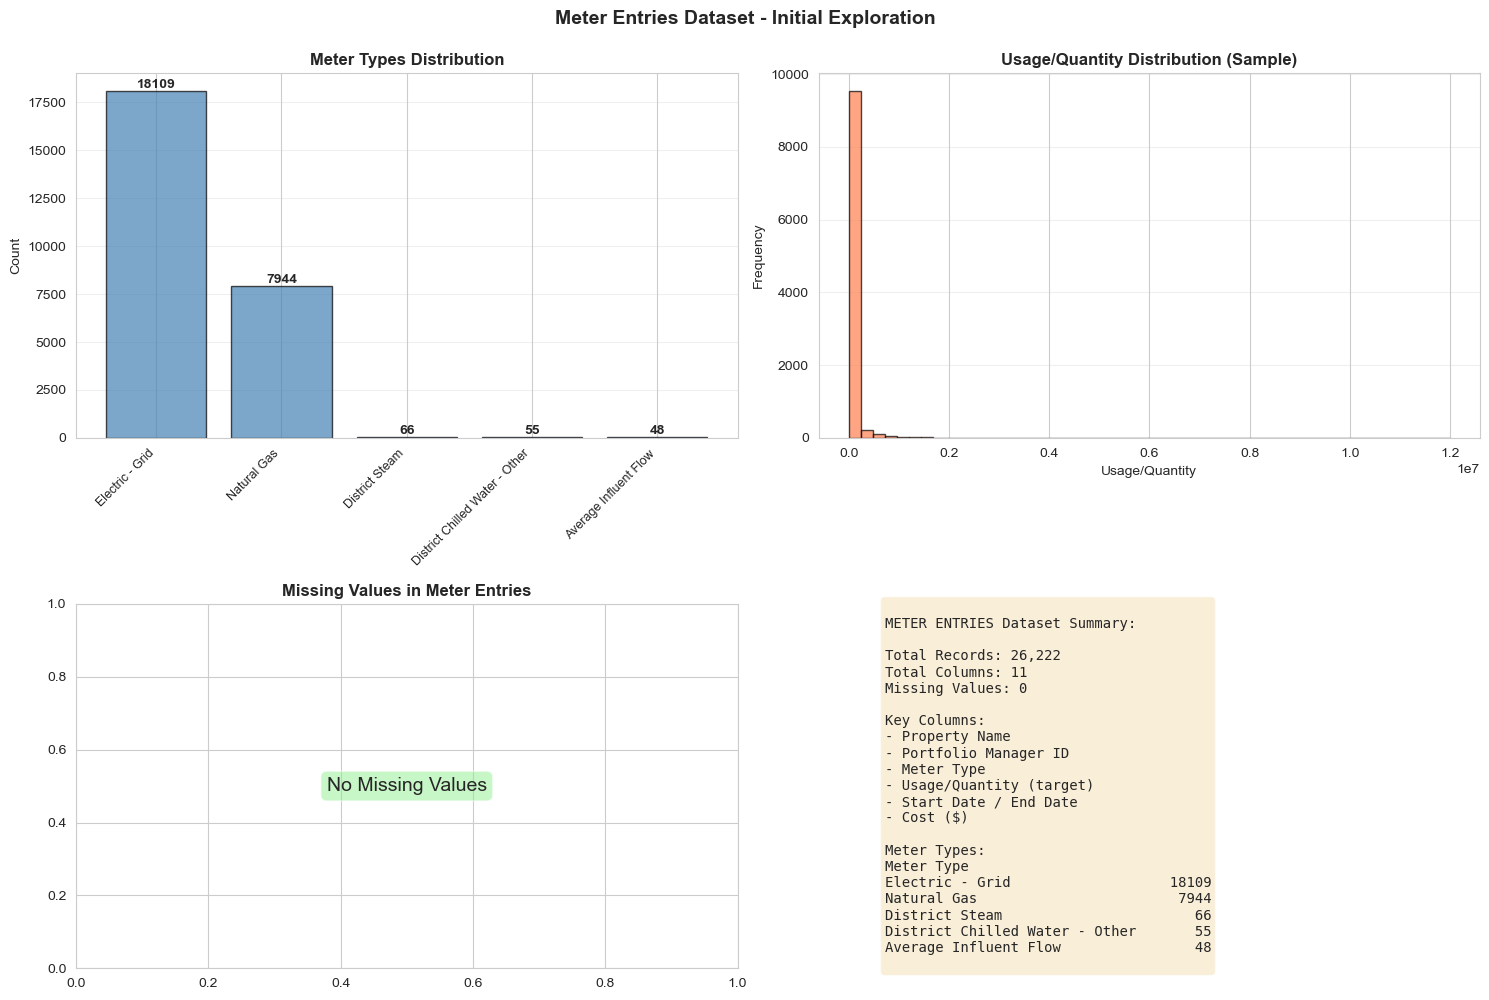

In [3]:
# STEP 1: Explore METER ENTRIES dataset
# This is our main dataset containing monthly consumption readings

print("=" * 80)
print("DATASET 1: METER ENTRIES")
print("=" * 80)
print(f"Shape: {meter_entries.shape[0]} rows × {meter_entries.shape[1]} columns")
print(f"\nColumns: {list(meter_entries.columns)}")
print("\n" + "-" * 80)
print("First 5 rows:")
print("-" * 80)
print(meter_entries.head())
print("\n" + "-" * 80)
print("Data types and missing values:")
print("-" * 80)
print(meter_entries.info())
print("\n" + "-" * 80)
print("Summary statistics for numerical columns:")
print("-" * 80)
print(meter_entries.describe())
print("\n" + "-" * 80)
print("Missing values count:")
print("-" * 80)
missing_meter_entries = meter_entries.isnull().sum()
print(missing_meter_entries[missing_meter_entries > 0])
if missing_meter_entries.sum() == 0:
    print("No missing values found!")
print("\n" + "-" * 80)
print("Meter types distribution:")
print("-" * 80)
meter_type_counts = meter_entries['Meter Type'].value_counts()
print(meter_type_counts)
print("\n")

# VISUALIZATION: Meter Entries dataset
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Plot 1: Meter types distribution
axes[0, 0].bar(range(len(meter_type_counts)), meter_type_counts.values, 
               color='steelblue', edgecolor='black', alpha=0.7)
axes[0, 0].set_xticks(range(len(meter_type_counts)))
axes[0, 0].set_xticklabels(meter_type_counts.index, rotation=45, ha='right', fontsize=9)
axes[0, 0].set_ylabel('Count', fontsize=10)
axes[0, 0].set_title('Meter Types Distribution', fontsize=12, fontweight='bold')
axes[0, 0].grid(axis='y', alpha=0.3)
for i, v in enumerate(meter_type_counts.values):
    axes[0, 0].text(i, v, str(v), ha='center', va='bottom', fontweight='bold')

# Plot 2: Usage/Quantity distribution (if numeric)
if pd.api.types.is_numeric_dtype(meter_entries['Usage/Quantity']):
    sample_data = meter_entries['Usage/Quantity'].dropna()
    if len(sample_data) > 10000:
        sample_data = sample_data.sample(10000, random_state=42)
    axes[0, 1].hist(sample_data, bins=50, color='coral', edgecolor='black', alpha=0.7)
    axes[0, 1].set_xlabel('Usage/Quantity', fontsize=10)
    axes[0, 1].set_ylabel('Frequency', fontsize=10)
    axes[0, 1].set_title('Usage/Quantity Distribution (Sample)', fontsize=12, fontweight='bold')
    axes[0, 1].grid(axis='y', alpha=0.3)
else:
    axes[0, 1].text(0.5, 0.5, 'Usage/Quantity is not numeric', 
                   ha='center', va='center', fontsize=12)
    axes[0, 1].set_title('Usage/Quantity Distribution', fontsize=12, fontweight='bold')

# Plot 3: Missing values visualization
missing_counts = meter_entries.isnull().sum()
missing_counts = missing_counts[missing_counts > 0]
if len(missing_counts) > 0:
    axes[1, 0].barh(range(len(missing_counts)), missing_counts.values, 
                    color='crimson', edgecolor='black', alpha=0.7)
    axes[1, 0].set_yticks(range(len(missing_counts)))
    axes[1, 0].set_yticklabels(missing_counts.index, fontsize=9)
    axes[1, 0].set_xlabel('Number of Missing Values', fontsize=10)
    axes[1, 0].set_title('Missing Values in Meter Entries', fontsize=12, fontweight='bold')
    axes[1, 0].grid(axis='x', alpha=0.3)
else:
    axes[1, 0].text(0.5, 0.5, 'No Missing Values', ha='center', va='center', 
                   fontsize=14, bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.5))
    axes[1, 0].set_title('Missing Values in Meter Entries', fontsize=12, fontweight='bold')

# Plot 4: Dataset overview summary
axes[1, 1].axis('off')
summary_text = f"""
METER ENTRIES Dataset Summary:

Total Records: {len(meter_entries):,}
Total Columns: {meter_entries.shape[1]}
Missing Values: {meter_entries.isnull().sum().sum()}

Key Columns:
- Property Name
- Portfolio Manager ID
- Meter Type
- Usage/Quantity (target)
- Start Date / End Date
- Cost ($)

Meter Types:
{meter_type_counts.to_string()}
"""
axes[1, 1].text(0.1, 0.5, summary_text, fontsize=10, family='monospace',
                verticalalignment='center', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.suptitle('Meter Entries Dataset - Initial Exploration', 
             fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()
print("\n")

DATASET 2: METERS
Shape: 2585 rows × 8 columns

Columns: ['Property Name', 'Portfolio Manager ID', 'Portfolio Manager Meter ID', 'Meter Name', 'Meter Type', 'Units', 'First Day of First Meter Entry', 'Last Day of Last Meter Entry']

--------------------------------------------------------------------------------
First 5 rows:
--------------------------------------------------------------------------------
         Property Name  Portfolio Manager ID  Portfolio Manager Meter ID  \
0  #13 Police Division              35000258                   189947941   
1  #13 Police Division              35000258                   189947942   
2  #22 Police Division              35000260                   189947959   
3  #22 Police Division              35000260                   189947960   
4  #23 Police Division              35000261                   189947990   

                             Meter Name       Meter Type  \
0     AUTO_#13 Police Division-Electric  Electric - Grid   
1  AUTO_#13 Po

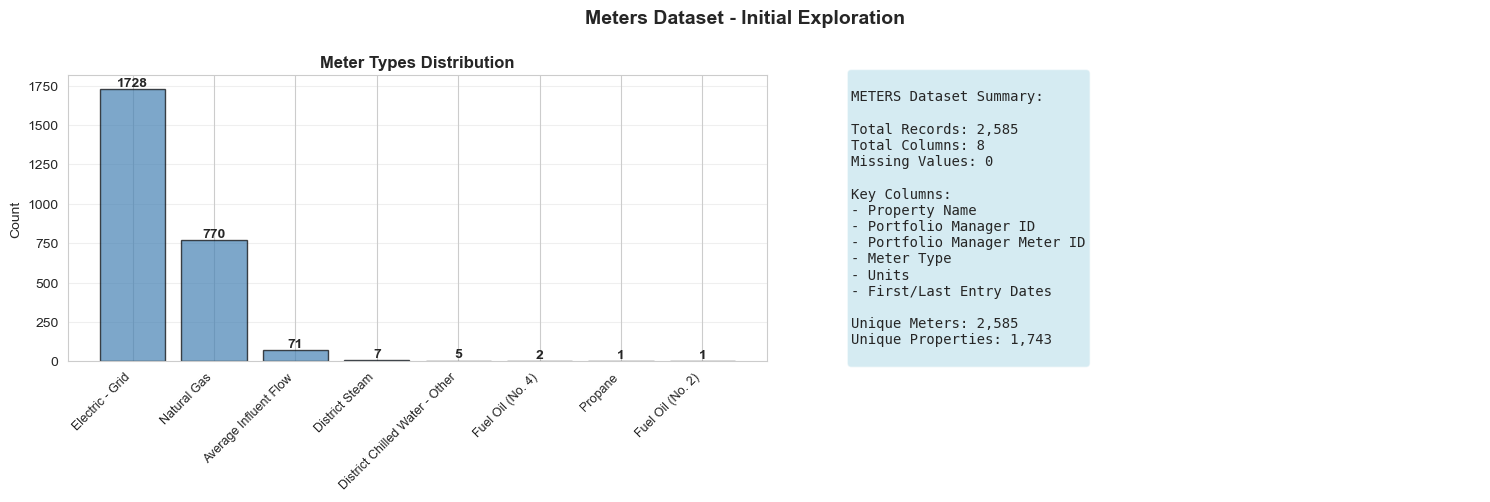

In [4]:
# STEP 2: Explore METERS dataset
# This dataset contains information about meters installed at each property

print("=" * 80)
print("DATASET 2: METERS")
print("=" * 80)
print(f"Shape: {meters.shape[0]} rows × {meters.shape[1]} columns")
print(f"\nColumns: {list(meters.columns)}")
print("\n" + "-" * 80)
print("First 5 rows:")
print("-" * 80)
print(meters.head())
print("\n" + "-" * 80)
print("Data types and missing values:")
print("-" * 80)
print(meters.info())
print("\n" + "-" * 80)
print("Meter types distribution:")
print("-" * 80)
meters_type_counts = meters['Meter Type'].value_counts()
print(meters_type_counts)
print("\n" + "-" * 80)
print("Missing values count:")
print("-" * 80)
missing_meters = meters.isnull().sum()
print(missing_meters[missing_meters > 0])
if missing_meters.sum() == 0:
    print("No missing values found!")
print("\n")
# VISUALIZATION: Meters dataset
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Meter types distribution
axes[0].bar(range(len(meters_type_counts)), meters_type_counts.values, 
            color='steelblue', edgecolor='black', alpha=0.7)
axes[0].set_xticks(range(len(meters_type_counts)))
axes[0].set_xticklabels(meters_type_counts.index, rotation=45, ha='right', fontsize=9)
axes[0].set_ylabel('Count', fontsize=10)
axes[0].set_title('Meter Types Distribution', fontsize=12, fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)
for i, v in enumerate(meters_type_counts.values):
    axes[0].text(i, v, str(v), ha='center', va='bottom', fontweight='bold')

# Plot 2: Dataset summary
axes[1].axis('off')
summary_text = f"""
METERS Dataset Summary:

Total Records: {len(meters):,}
Total Columns: {meters.shape[1]}
Missing Values: {meters.isnull().sum().sum()}

Key Columns:
- Property Name
- Portfolio Manager ID
- Portfolio Manager Meter ID
- Meter Type
- Units
- First/Last Entry Dates

Unique Meters: {meters['Portfolio Manager Meter ID'].nunique():,}
Unique Properties: {meters['Portfolio Manager ID'].nunique():,}
"""
axes[1].text(0.1, 0.5, summary_text, fontsize=10, family='monospace',
            verticalalignment='center', bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.5))

plt.suptitle('Meters Dataset - Initial Exploration', 
             fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()
print("\n")

DATASET 3: PROPERTIES
Shape: 1760 rows × 8 columns

Columns: ['Property Name', 'Portfolio Manager ID', 'Street Address', 'City/Municipality', 'Postal Code', 'Property Type - Self-Selected', 'Gross Floor Area', 'Occupancy (%)']

--------------------------------------------------------------------------------
First 5 rows:
--------------------------------------------------------------------------------
               Property Name  Portfolio Manager ID         Street Address  \
0  #11 Police Division - OLD              34999087          209 MAVETY ST   
1  #14 Police Division - OLD              34999088        150 HARRISON ST   
2      175 Memorial Park Ave              34999089  175 MEMORIAL PARK AVE   
3                18 Dyas Rd.              34999090             18 DYAS RD   
4       2 Civic Centre Court              34999091     2 CIVIC CENTRE CRT   

  City/Municipality Postal Code Property Type - Self-Selected  \
0           Toronto     M6P 2M1                        Office   
1  

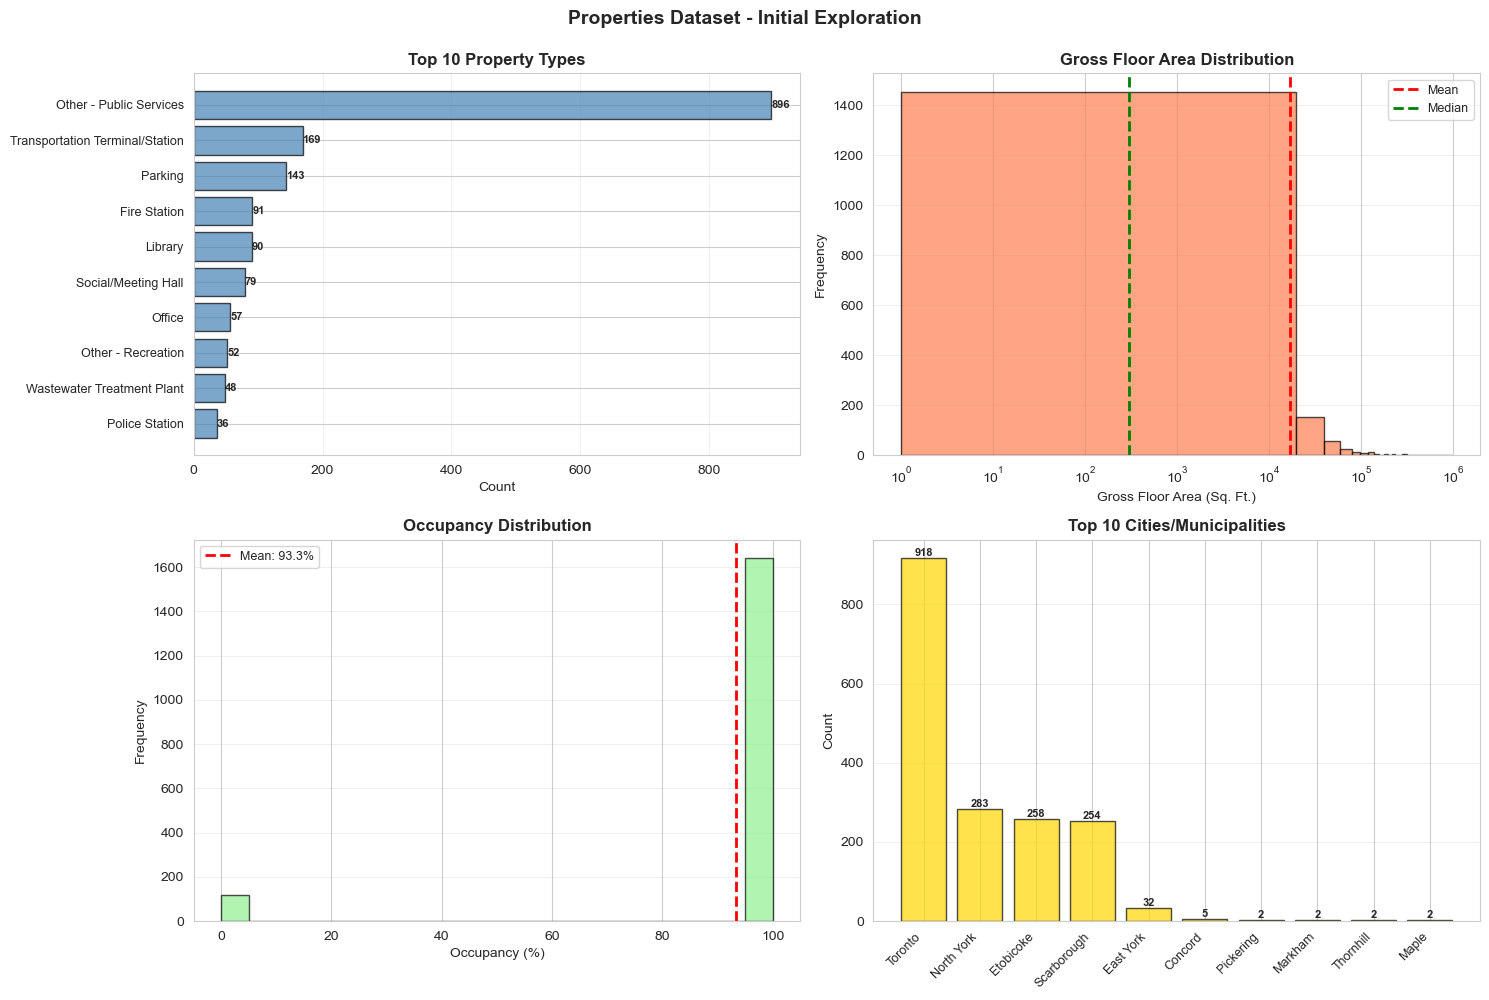

In [5]:
# STEP 3: Explore PROPERTIES dataset
# This dataset contains property characteristics

print("=" * 80)
print("DATASET 3: PROPERTIES")
print("=" * 80)
print(f"Shape: {properties.shape[0]} rows × {properties.shape[1]} columns")
print(f"\nColumns: {list(properties.columns)}")
print("\n" + "-" * 80)
print("First 5 rows:")
print("-" * 80)
print(properties.head())
print("\n" + "-" * 80)
print("Data types and missing values:")
print("-" * 80)
print(properties.info())
print("\n" + "-" * 80)
print("Summary statistics for numerical columns:")
print("-" * 80)
print(properties.describe())
print("\n" + "-" * 80)
print("Missing values count:")
print("-" * 80)
missing_properties = properties.isnull().sum()
print(missing_properties[missing_properties > 0])
if missing_properties.sum() == 0:
    print("No missing values found!")
print("\n" + "-" * 80)
print("Property types distribution (top 10):")
print("-" * 80)
if 'Property Type - Self-Selected' in properties.columns:
    prop_types = properties['Property Type - Self-Selected'].value_counts().head(10)
    print(prop_types)
print("\n")

# VISUALIZATION: Properties dataset analysis
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Plot 1: Property types distribution (top 10)
if 'Property Type - Self-Selected' in properties.columns:
    prop_types = properties['Property Type - Self-Selected'].value_counts().head(10)
    axes[0, 0].barh(range(len(prop_types)), prop_types.values, color='steelblue', edgecolor='black', alpha=0.7)
    axes[0, 0].set_yticks(range(len(prop_types)))
    axes[0, 0].set_yticklabels(prop_types.index, fontsize=9)
    axes[0, 0].set_xlabel('Count', fontsize=10)
    axes[0, 0].set_title('Top 10 Property Types', fontsize=12, fontweight='bold')
    axes[0, 0].grid(axis='x', alpha=0.3)
    axes[0, 0].invert_yaxis()
    for i, v in enumerate(prop_types.values):
        axes[0, 0].text(v, i, str(v), va='center', ha='left', fontsize=8, fontweight='bold')

# Plot 2: Gross Floor Area distribution
if 'Gross Floor Area' in properties.columns:
    floor_area = pd.to_numeric(properties['Gross Floor Area'], errors='coerce').dropna()
    floor_area = floor_area[floor_area > 0]  # Remove invalid values
    if len(floor_area) > 0:
        axes[0, 1].hist(floor_area, bins=50, color='coral', edgecolor='black', alpha=0.7)
        axes[0, 1].set_xlabel('Gross Floor Area (Sq. Ft.)', fontsize=10)
        axes[0, 1].set_ylabel('Frequency', fontsize=10)
        axes[0, 1].set_title('Gross Floor Area Distribution', fontsize=12, fontweight='bold')
        axes[0, 1].set_xscale('log')
        axes[0, 1].grid(axis='y', alpha=0.3)
        axes[0, 1].axvline(floor_area.mean(), color='r', linestyle='--', linewidth=2, label='Mean')
        axes[0, 1].axvline(floor_area.median(), color='g', linestyle='--', linewidth=2, label='Median')
        axes[0, 1].legend(fontsize=9)

# Plot 3: Occupancy distribution
if 'Occupancy (%)' in properties.columns:
    occupancy = pd.to_numeric(properties['Occupancy (%)'], errors='coerce').dropna()
    if len(occupancy) > 0:
        axes[1, 0].hist(occupancy, bins=20, color='lightgreen', edgecolor='black', alpha=0.7)
        axes[1, 0].set_xlabel('Occupancy (%)', fontsize=10)
        axes[1, 0].set_ylabel('Frequency', fontsize=10)
        axes[1, 0].set_title('Occupancy Distribution', fontsize=12, fontweight='bold')
        axes[1, 0].grid(axis='y', alpha=0.3)
        axes[1, 0].axvline(occupancy.mean(), color='r', linestyle='--', linewidth=2, label=f'Mean: {occupancy.mean():.1f}%')
        axes[1, 0].legend(fontsize=9)

# Plot 4: Cities/Municipalities distribution (top 10)
if 'City/Municipality' in properties.columns:
    cities = properties['City/Municipality'].value_counts().head(10)
    axes[1, 1].bar(range(len(cities)), cities.values, color='gold', edgecolor='black', alpha=0.7)
    axes[1, 1].set_xticks(range(len(cities)))
    axes[1, 1].set_xticklabels(cities.index, rotation=45, ha='right', fontsize=9)
    axes[1, 1].set_ylabel('Count', fontsize=10)
    axes[1, 1].set_title('Top 10 Cities/Municipalities', fontsize=12, fontweight='bold')
    axes[1, 1].grid(axis='y', alpha=0.3)
    for i, v in enumerate(cities.values):
        axes[1, 1].text(i, v, str(v), ha='center', va='bottom', fontsize=8, fontweight='bold')

plt.suptitle('Properties Dataset - Initial Exploration', 
             fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()
print("\n")


DATASET 4: USES
Shape: 1760 rows × 7 columns

Columns: ['Property Name', 'Portfolio Manager ID', 'Property Use Name', 'Use Type', 'Gross Floor Area for Use', 'Gross Floor Area Units', 'Gross Floor Area Temporary Value? (Y/N)']

--------------------------------------------------------------------------------
First 5 rows:
--------------------------------------------------------------------------------
               Property Name  Portfolio Manager ID Property Use Name Use Type  \
0  #11 Police Division - OLD              34999087      Building Use   Office   
1  #14 Police Division - OLD              34999088      Building Use   Office   
2      175 Memorial Park Ave              34999089      Building Use   Office   
3                18 Dyas Rd.              34999090      Building Use   Office   
4       2 Civic Centre Court              34999091      Building Use   Office   

   Gross Floor Area for Use Gross Floor Area Units  \
0                   21119.0                Sq. Ft.   
1

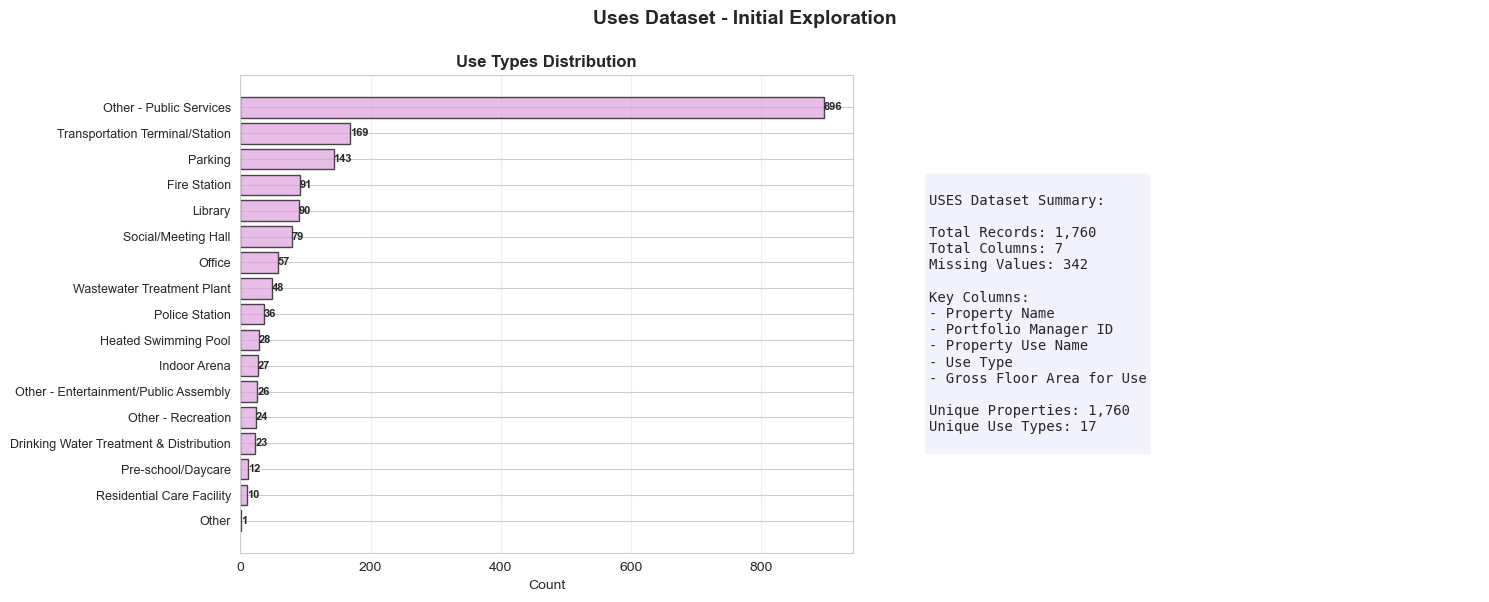

In [6]:
# STEP 4: Explore USES dataset
# This dataset contains floor area allocation by use type for each property

print("=" * 80)
print("DATASET 4: USES")
print("=" * 80)
print(f"Shape: {uses.shape[0]} rows × {uses.shape[1]} columns")
print(f"\nColumns: {list(uses.columns)}")
print("\n" + "-" * 80)
print("First 5 rows:")
print("-" * 80)
print(uses.head())
print("\n" + "-" * 80)
print("Data types and missing values:")
print("-" * 80)
print(uses.info())
print("\n" + "-" * 80)
print("Summary statistics for numerical columns:")
print("-" * 80)
print(uses.describe())
print("\n" + "-" * 80)
print("Missing values count:")
print("-" * 80)
missing_uses = uses.isnull().sum()
print(missing_uses[missing_uses > 0])
if missing_uses.sum() == 0:
    print("No missing values found!")
print("\n" + "-" * 80)
print("Use types distribution:")
print("-" * 80)
if 'Use Type' in uses.columns:
    use_types = uses['Use Type'].value_counts()
    print(use_types)
print("\n")

# VISUALIZATION: Uses dataset
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Use types distribution
if 'Use Type' in uses.columns:
    use_types = uses['Use Type'].value_counts()
    axes[0].barh(range(len(use_types)), use_types.values, color='plum', edgecolor='black', alpha=0.7)
    axes[0].set_yticks(range(len(use_types)))
    axes[0].set_yticklabels(use_types.index, fontsize=9)
    axes[0].set_xlabel('Count', fontsize=10)
    axes[0].set_title('Use Types Distribution', fontsize=12, fontweight='bold')
    axes[0].grid(axis='x', alpha=0.3)
    axes[0].invert_yaxis()
    for i, v in enumerate(use_types.values):
        axes[0].text(v, i, str(v), va='center', ha='left', fontsize=8, fontweight='bold')

# Plot 2: Dataset summary
axes[1].axis('off')
if 'Use Type' in uses.columns:
    use_types_str = use_types.to_string()
else:
    use_types_str = "N/A"

summary_text = f"""
USES Dataset Summary:

Total Records: {len(uses):,}
Total Columns: {uses.shape[1]}
Missing Values: {uses.isnull().sum().sum()}

Key Columns:
- Property Name
- Portfolio Manager ID
- Property Use Name
- Use Type
- Gross Floor Area for Use

Unique Properties: {uses['Portfolio Manager ID'].nunique():,}
Unique Use Types: {len(use_types) if 'Use Type' in uses.columns else 'N/A'}
"""
axes[1].text(0.1, 0.5, summary_text, fontsize=10, family='monospace',
            verticalalignment='center', bbox=dict(boxstyle='round', facecolor='lavender', alpha=0.5))

plt.suptitle('Uses Dataset - Initial Exploration', 
             fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()
print("\n")


ELECTRIC - GRID METERS ANALYSIS

Total Electric - Grid meter entries: 18,109
Percentage of total meter entries: 69.1%

Valid usage values: 18,109
Missing/invalid usage values: 0

--------------------------------------------------------------------------------
Usage/Quantity statistics for Electric - Grid meters:
--------------------------------------------------------------------------------
count    1.810900e+04
mean     7.597673e+04
std      4.083190e+05
min      0.000000e+00
25%      5.376500e+02
50%      4.321070e+03
75%      2.423638e+04
max      1.199675e+07
Name: Usage/Quantity, dtype: float64


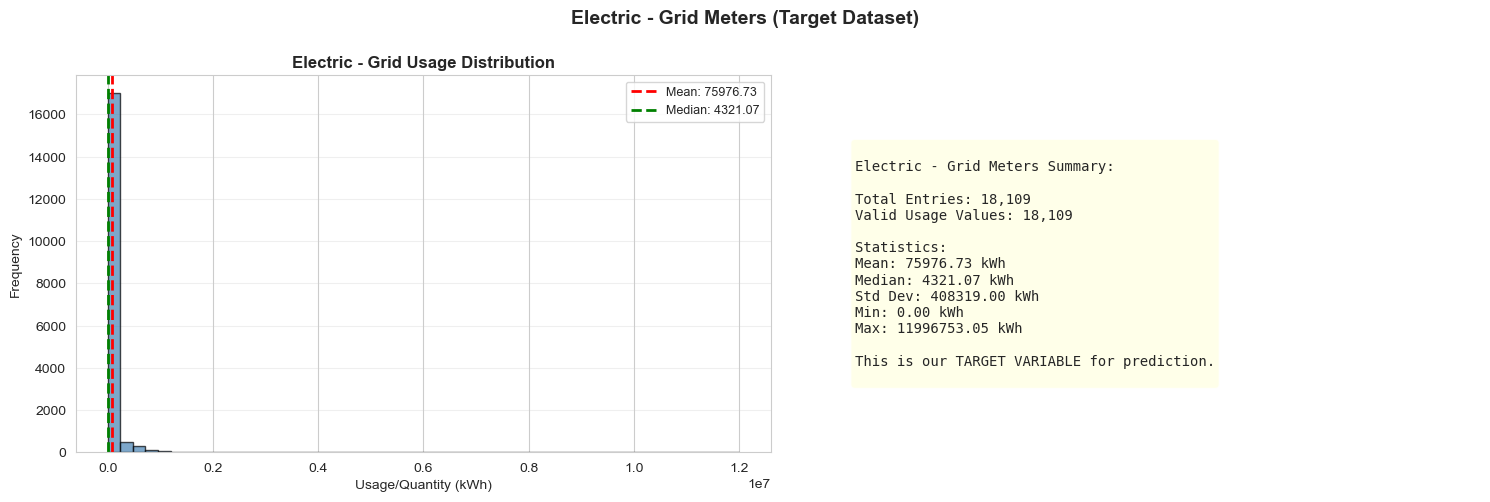

In [7]:
# STEP 5: Check Electric - Grid meters (our target data)
# We need to filter for "Electric - Grid" meters only as per project requirements

print("=" * 80)
print("ELECTRIC - GRID METERS ANALYSIS")
print("=" * 80)

# Filter for Electric - Grid meters in meter_entries
electric_meters = meter_entries[meter_entries['Meter Type'] == 'Electric - Grid'].copy()
print(f"\nTotal Electric - Grid meter entries: {len(electric_meters):,}")
print(f"Percentage of total meter entries: {len(electric_meters)/len(meter_entries)*100:.1f}%")

# Convert Usage/Quantity to numeric if it's not already
electric_meters['Usage/Quantity'] = pd.to_numeric(electric_meters['Usage/Quantity'], errors='coerce')
valid_usage = electric_meters['Usage/Quantity'].dropna()

print(f"\nValid usage values: {len(valid_usage):,}")
print(f"Missing/invalid usage values: {len(electric_meters) - len(valid_usage):,}")

print("\n" + "-" * 80)
print("Usage/Quantity statistics for Electric - Grid meters:")
print("-" * 80)
electric_stats = valid_usage.describe()
print(electric_stats)

# VISUALIZATION: Electric - Grid meters
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
# Plot 1: Distribution of Electric - Grid usage
if len(valid_usage) > 0:
    axes[0].hist(valid_usage, bins=50, color='steelblue', edgecolor='black', alpha=0.7)
    axes[0].axvline(valid_usage.mean(), color='r', linestyle='--', linewidth=2, 
                    label=f'Mean: {valid_usage.mean():.2f}')
    axes[0].axvline(valid_usage.median(), color='g', linestyle='--', linewidth=2, 
                    label=f'Median: {valid_usage.median():.2f}')
    axes[0].set_xlabel('Usage/Quantity (kWh)', fontsize=10)
    axes[0].set_ylabel('Frequency', fontsize=10)
    axes[0].set_title('Electric - Grid Usage Distribution', fontsize=12, fontweight='bold')
    axes[0].legend(fontsize=9)
    axes[0].grid(axis='y', alpha=0.3)

# Plot 2: Summary statistics
axes[1].axis('off')
summary_text = f"""
Electric - Grid Meters Summary:

Total Entries: {len(electric_meters):,}
Valid Usage Values: {len(valid_usage):,}

Statistics:
Mean: {valid_usage.mean():.2f} kWh
Median: {valid_usage.median():.2f} kWh
Std Dev: {valid_usage.std():.2f} kWh
Min: {valid_usage.min():.2f} kWh
Max: {valid_usage.max():.2f} kWh

This is our TARGET VARIABLE for prediction.
"""
axes[1].text(0.1, 0.5, summary_text, fontsize=10, family='monospace',
            verticalalignment='center', bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.7))

plt.suptitle('Electric - Grid Meters (Target Dataset)', 
             fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

## 4. Data Cleaning

Now we'll clean the data by:
1. Filtering for Electric - Grid meters only (as per project requirements)
2. Handling missing values
3. Removing duplicates
4. Converting data types appropriately
5. Handling placeholder values like "Not Available"

In [8]:
# STEP 1: Filter for Electric - Grid meters only
# This is our target dataset as specified in the project requirements
print("Filtering for Electric - Grid meters...")
electric_data = meter_entries[meter_entries['Meter Type'] == 'Electric - Grid'].copy()
print(f"Original meter_entries rows: {len(meter_entries)}")
print(f"Electric - Grid rows: {len(electric_data)}")
print(f"Rows filtered out: {len(meter_entries) - len(electric_data)}")
print("\n")

Filtering for Electric - Grid meters...
Original meter_entries rows: 26222
Electric - Grid rows: 18109
Rows filtered out: 8113




In [9]:
# STEP 2: Convert date columns to datetime format
# This will help us extract temporal features later
print("Converting date columns to datetime format...")
electric_data['Start Date'] = pd.to_datetime(electric_data['Start Date'], errors='coerce')
electric_data['End Date'] = pd.to_datetime(electric_data['End Date'], errors='coerce')

# Check for any conversion errors (NaT values)
start_date_nat = electric_data['Start Date'].isna().sum()
end_date_nat = electric_data['End Date'].isna().sum()
print(f"Start Date NaT values: {start_date_nat}")
print(f"End Date NaT values: {end_date_nat}")

# Remove rows with invalid dates
if start_date_nat > 0 or end_date_nat > 0:
    electric_data = electric_data.dropna(subset=['Start Date', 'End Date'])
    print(f"Removed {start_date_nat + end_date_nat} rows with invalid dates")
    print(f"Remaining rows: {len(electric_data)}")
print("\n")

Converting date columns to datetime format...
Start Date NaT values: 0
End Date NaT values: 0




In [10]:
# STEP 3: Handle the target variable (Usage/Quantity)
# Check for missing or invalid values in Usage/Quantity
print("Checking Usage/Quantity (target variable)...")
print(f"Missing values: {electric_data['Usage/Quantity'].isna().sum()}")
print(f"Zero values: {(electric_data['Usage/Quantity'] == 0).sum()}")
print(f"Negative values: {(electric_data['Usage/Quantity'] < 0).sum()}")

# Remove rows with missing or invalid usage values
# Zero or negative consumption doesn't make sense for our prediction task
initial_rows = len(electric_data)
electric_data = electric_data[
    (electric_data['Usage/Quantity'].notna()) & 
    (electric_data['Usage/Quantity'] > 0)
].copy()
print(f"Removed {initial_rows - len(electric_data)} rows with invalid usage values")
print(f"Remaining rows: {len(electric_data)}")
print("\n")


Checking Usage/Quantity (target variable)...
Missing values: 0
Zero values: 389
Negative values: 0
Removed 389 rows with invalid usage values
Remaining rows: 17720




In [11]:
# STEP 4: Check for duplicates
print("Checking for duplicate rows...")
duplicates = electric_data.duplicated().sum()
print(f"Duplicate rows: {duplicates}")

if duplicates > 0:
    electric_data = electric_data.drop_duplicates()
    print(f"Removed {duplicates} duplicate rows")
    print(f"Remaining rows: {len(electric_data)}")
print("\n")

Checking for duplicate rows...
Duplicate rows: 0




In [12]:
# STEP 5: Clean properties dataset
# Handle "Not Available" and missing values
print("Cleaning properties dataset...")
print(f"Properties shape before cleaning: {properties.shape}")

# Replace "Not Available" with NaN for proper handling
properties_clean = properties.replace('Not Available', np.nan)

# Check for missing values
print("\nMissing values in properties:")
print(properties_clean.isnull().sum())

# Handle Gross Floor Area - convert to numeric, handle missing values
properties_clean['Gross Floor Area'] = pd.to_numeric(properties_clean['Gross Floor Area'], errors='coerce')

# Handle Occupancy - convert to numeric
properties_clean['Occupancy (%)'] = pd.to_numeric(properties_clean['Occupancy (%)'], errors='coerce')

print(f"\nProperties shape after cleaning: {properties_clean.shape}")
print("\n")

Cleaning properties dataset...
Properties shape before cleaning: (1760, 8)

Missing values in properties:
Property Name                    0
Portfolio Manager ID             0
Street Address                   0
City/Municipality                0
Postal Code                      0
Property Type - Self-Selected    0
Gross Floor Area                 0
Occupancy (%)                    0
dtype: int64

Properties shape after cleaning: (1760, 8)




In [13]:
# STEP 6: Clean uses dataset
# Aggregate floor area by property and use type
print("Cleaning uses dataset...")
print(f"Uses shape before cleaning: {uses.shape}")

# Convert Gross Floor Area for Use to numeric
uses_clean = uses.copy()
uses_clean['Gross Floor Area for Use'] = pd.to_numeric(
    uses_clean['Gross Floor Area for Use'], 
    errors='coerce'
)

# Remove rows with invalid floor area values
uses_clean = uses_clean[uses_clean['Gross Floor Area for Use'] > 0].copy()

print(f"Uses shape after cleaning: {uses_clean.shape}")
print("\n")


Cleaning uses dataset...
Uses shape before cleaning: (1760, 7)
Uses shape after cleaning: (995, 7)




## 5. Data Merging and Feature Preparation

Now we'll merge the datasets to create a comprehensive feature set for our model.


In [14]:
# STEP 1: Merge electric_data with properties using Portfolio Manager ID
# This will add property characteristics to each meter reading
print("Merging electric data with properties...")
merged_data = electric_data.merge(
    properties_clean,
    on='Portfolio Manager ID',
    how='left',
    suffixes=('', '_property')
)
print(f"Merged data shape: {merged_data.shape}")
print(f"Rows with property info: {merged_data['Gross Floor Area'].notna().sum()}")
print("\n")

Merging electric data with properties...
Merged data shape: (17720, 18)
Rows with property info: 17720




In [15]:
# STEP 2: Aggregate uses data by property
# Calculate total floor area by use type for each property
print("Aggregating uses data by property...")

# Create a pivot table to get floor area by use type for each property
uses_pivot = uses_clean.pivot_table(
    index='Portfolio Manager ID',
    columns='Use Type',
    values='Gross Floor Area for Use',
    aggfunc='sum',
    fill_value=0
)

# Rename columns to indicate they're floor areas by use type
uses_pivot.columns = [f'Floor_Area_{col.replace(" ", "_").replace("/", "_")}' for col in uses_pivot.columns]

print(f"Uses pivot shape: {uses_pivot.shape}")
print(f"Use types: {list(uses_pivot.columns)}")
print("\n")

Aggregating uses data by property...
Uses pivot shape: (995, 15)
Use types: ['Floor_Area_Drinking_Water_Treatment_&_Distribution', 'Floor_Area_Fire_Station', 'Floor_Area_Indoor_Arena', 'Floor_Area_Library', 'Floor_Area_Office', 'Floor_Area_Other', 'Floor_Area_Other_-_Entertainment_Public_Assembly', 'Floor_Area_Other_-_Public_Services', 'Floor_Area_Other_-_Recreation', 'Floor_Area_Police_Station', 'Floor_Area_Pre-school_Daycare', 'Floor_Area_Residential_Care_Facility', 'Floor_Area_Social_Meeting_Hall', 'Floor_Area_Transportation_Terminal_Station', 'Floor_Area_Wastewater_Treatment_Plant']




In [16]:
# STEP 3: Merge uses data with merged_data
print("Merging uses data...")
merged_data = merged_data.merge(
    uses_pivot,
    left_on='Portfolio Manager ID',
    right_index=True,
    how='left'
)

# Fill NaN values with 0 for use type floor areas (property has no such use type)
use_cols = [col for col in merged_data.columns if col.startswith('Floor_Area_')]
merged_data[use_cols] = merged_data[use_cols].fillna(0)

print(f"Final merged data shape: {merged_data.shape}")
print("\n")

Merging uses data...
Final merged data shape: (17720, 33)




## 6. Feature Engineering

We'll create new features that might help predict electricity consumption:
1. Temporal features from dates (month, year, season)
2. Property size features
3. Derived features from existing data


In [17]:
# STEP 1: Extract temporal features from Start Date
# These features capture seasonal patterns in electricity consumption
print("Creating temporal features...")

# Extract month (1-12) - captures seasonal patterns
merged_data['Month'] = merged_data['Start Date'].dt.month

# Extract year - captures long-term trends
merged_data['Year'] = merged_data['Start Date'].dt.year

# Extract season (1=Winter, 2=Spring, 3=Summer, 4=Fall)
# Winter: Dec(12), Jan(1), Feb(2)
# Spring: Mar(3), Apr(4), May(5)
# Summer: Jun(6), Jul(7), Aug(8)
# Fall: Sep(9), Oct(10), Nov(11)
def get_season(month):
    if month in [12, 1, 2]:
        return 1  # Winter
    elif month in [3, 4, 5]:
        return 2  # Spring
    elif month in [6, 7, 8]:
        return 3  # Summer
    else:
        return 4  # Fall

merged_data['Season'] = merged_data['Month'].apply(get_season)

# Extract day of year (1-365) - captures gradual seasonal changes
merged_data['DayOfYear'] = merged_data['Start Date'].dt.dayofyear

# Calculate days in billing period (might affect consumption patterns)
merged_data['DaysInPeriod'] = (merged_data['End Date'] - merged_data['Start Date']).dt.days

print("Temporal features created:")
print(f"  - Month: {merged_data['Month'].nunique()} unique values")
print(f"  - Year: {merged_data['Year'].nunique()} unique values")
print(f"  - Season: {merged_data['Season'].nunique()} unique values")
print(f"  - DaysInPeriod: mean={merged_data['DaysInPeriod'].mean():.1f} days")
print("\n")


Creating temporal features...
Temporal features created:
  - Month: 11 unique values
  - Year: 1 unique values
  - Season: 4 unique values
  - DaysInPeriod: mean=30.3 days




In [18]:
# STEP 2: Create property size features
print("Creating property size features...")

# Use Gross Floor Area as a key feature (larger buildings consume more)
# Create a flag for missing floor area
merged_data['Has_Floor_Area'] = merged_data['Gross Floor Area'].notna().astype(int)

# Fill missing floor area with median (we'll use median to avoid outlier influence)
if merged_data['Gross Floor Area'].isna().sum() > 0:
    median_floor_area = merged_data['Gross Floor Area'].median()
    merged_data['Gross Floor Area'] = merged_data['Gross Floor Area'].fillna(median_floor_area)
    print(f"Filled {merged_data['Has_Floor_Area'].sum()} missing floor areas with median: {median_floor_area:.2f}")

# Create normalized features (per square foot consumption might be more meaningful)
# We'll calculate this after we have the target variable ready

# Calculate total floor area from uses (sum of all use types)
merged_data['Total_Use_Floor_Area'] = merged_data[use_cols].sum(axis=1)

# If Total_Use_Floor_Area is 0 but Gross Floor Area exists, use Gross Floor Area
mask = (merged_data['Total_Use_Floor_Area'] == 0) & (merged_data['Gross Floor Area'].notna())
merged_data.loc[mask, 'Total_Use_Floor_Area'] = merged_data.loc[mask, 'Gross Floor Area']

print("Property size features created")
print("\n")

Creating property size features...
Property size features created




In [19]:
# STEP 3: Create derived features
print("Creating derived features...")

# Occupancy percentage (affects energy consumption)
merged_data['Occupancy (%)'] = pd.to_numeric(merged_data['Occupancy (%)'], errors='coerce')
merged_data['Occupancy (%)'] = merged_data['Occupancy (%)'].fillna(100)  # Assume 100% if missing

# Create property type encoding (we'll do proper encoding later, but create a flag now)
merged_data['Has_Property_Type'] = merged_data['Property Type - Self-Selected'].notna().astype(int)

# Create a feature for whether cost data is available (might indicate data quality)
merged_data['Has_Cost'] = merged_data['Cost ($)'].notna().astype(int)

# Calculate consumption per square foot (if floor area available)
merged_data['Usage_Per_SqFt'] = merged_data['Usage/Quantity'] / merged_data['Gross Floor Area']
# Replace inf values (division by zero) with NaN, then fill with median
merged_data['Usage_Per_SqFt'] = merged_data['Usage_Per_SqFt'].replace([np.inf, -np.inf], np.nan)
if merged_data['Usage_Per_SqFt'].notna().sum() > 0:
    median_usage_per_sqft = merged_data['Usage_Per_SqFt'].median()
    merged_data['Usage_Per_SqFt'] = merged_data['Usage_Per_SqFt'].fillna(median_usage_per_sqft)

print("Derived features created")
print("\n")

Creating derived features...
Derived features created




## 7. Exploratory Data Analysis (EDA)

Let's explore the data to understand patterns, distributions, and relationships.


TARGET VARIABLE ANALYSIS
Mean consumption: 77644.62 kWh
Median consumption: 4630.76 kWh
Std deviation: 412619.85 kWh
Min consumption: 0.01 kWh
Max consumption: 11996753.05 kWh
Skewness: 15.53




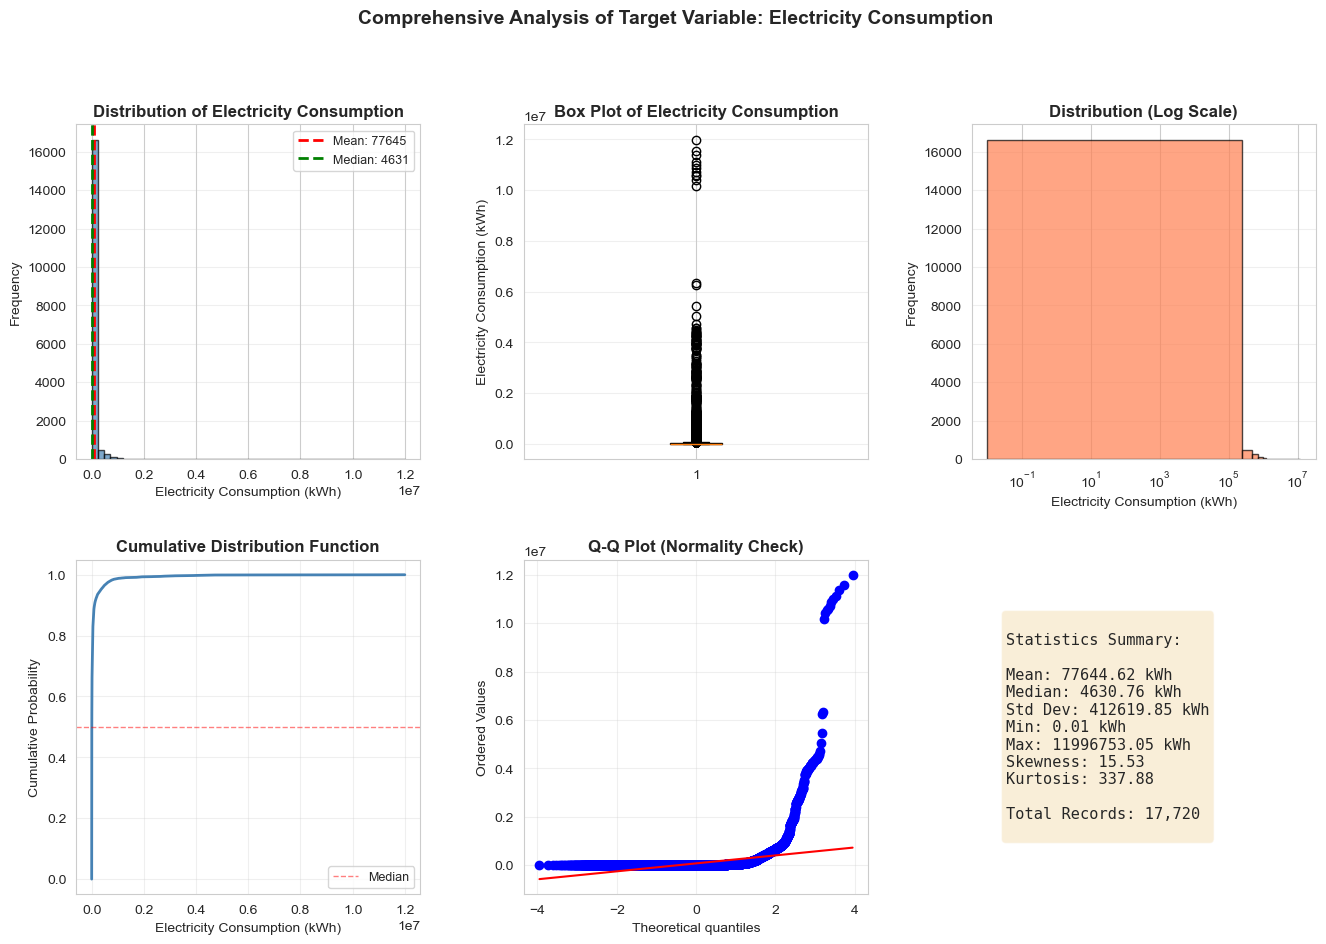

In [20]:
# EDA 1: Distribution of target variable (Usage/Quantity)
print("=" * 80)
print("TARGET VARIABLE ANALYSIS")
print("=" * 80)
print(f"Mean consumption: {merged_data['Usage/Quantity'].mean():.2f} kWh")
print(f"Median consumption: {merged_data['Usage/Quantity'].median():.2f} kWh")
print(f"Std deviation: {merged_data['Usage/Quantity'].std():.2f} kWh")
print(f"Min consumption: {merged_data['Usage/Quantity'].min():.2f} kWh")
print(f"Max consumption: {merged_data['Usage/Quantity'].max():.2f} kWh")
print(f"Skewness: {merged_data['Usage/Quantity'].skew():.2f}")
print("\n")

# Create comprehensive visualization using matplotlib.pyplot
fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(2, 3, hspace=0.3, wspace=0.3)

# Plot 1: Histogram (top left)
ax1 = fig.add_subplot(gs[0, 0])
ax1.hist(merged_data['Usage/Quantity'], bins=50, color='steelblue', edgecolor='black', alpha=0.7)
ax1.set_xlabel('Electricity Consumption (kWh)', fontsize=10)
ax1.set_ylabel('Frequency', fontsize=10)
ax1.set_title('Distribution of Electricity Consumption', fontsize=12, fontweight='bold')
ax1.axvline(merged_data['Usage/Quantity'].mean(), color='r', linestyle='--', linewidth=2, label=f'Mean: {merged_data["Usage/Quantity"].mean():.0f}')
ax1.axvline(merged_data['Usage/Quantity'].median(), color='g', linestyle='--', linewidth=2, label=f'Median: {merged_data["Usage/Quantity"].median():.0f}')
ax1.legend(fontsize=9)
ax1.grid(axis='y', alpha=0.3)

# Plot 2: Box plot (top middle)
ax2 = fig.add_subplot(gs[0, 1])
bp = ax2.boxplot(merged_data['Usage/Quantity'], vert=True, patch_artist=True)
bp['boxes'][0].set_facecolor('lightblue')
bp['boxes'][0].set_edgecolor('black')
ax2.set_ylabel('Electricity Consumption (kWh)', fontsize=10)
ax2.set_title('Box Plot of Electricity Consumption', fontsize=12, fontweight='bold')
ax2.grid(axis='y', alpha=0.3)

# Plot 3: Log scale histogram (top right) - better for skewed data
ax3 = fig.add_subplot(gs[0, 2])
ax3.hist(merged_data['Usage/Quantity'], bins=50, color='coral', edgecolor='black', alpha=0.7)
ax3.set_xlabel('Electricity Consumption (kWh)', fontsize=10)
ax3.set_ylabel('Frequency', fontsize=10)
ax3.set_title('Distribution (Log Scale)', fontsize=12, fontweight='bold')
ax3.set_xscale('log')
ax3.grid(axis='y', alpha=0.3)

# Plot 4: Cumulative distribution (bottom left)
ax4 = fig.add_subplot(gs[1, 0])
sorted_data = np.sort(merged_data['Usage/Quantity'])
cumulative = np.arange(1, len(sorted_data) + 1) / len(sorted_data)
ax4.plot(sorted_data, cumulative, color='steelblue', linewidth=2)
ax4.set_xlabel('Electricity Consumption (kWh)', fontsize=10)
ax4.set_ylabel('Cumulative Probability', fontsize=10)
ax4.set_title('Cumulative Distribution Function', fontsize=12, fontweight='bold')
ax4.grid(alpha=0.3)
ax4.axhline(0.5, color='r', linestyle='--', linewidth=1, alpha=0.5, label='Median')
ax4.legend(fontsize=9)

# Plot 5: Q-Q plot approximation (bottom middle)
# Note: scipy.stats is already imported at the top of the notebook
ax5 = fig.add_subplot(gs[1, 1])
stats.probplot(merged_data['Usage/Quantity'], dist="norm", plot=ax5)
ax5.set_title('Q-Q Plot (Normality Check)', fontsize=12, fontweight='bold')
ax5.grid(alpha=0.3)

# Plot 6: Statistics summary (bottom right) - text summary
ax6 = fig.add_subplot(gs[1, 2])
ax6.axis('off')
stats_text = f"""
Statistics Summary:

Mean: {merged_data['Usage/Quantity'].mean():.2f} kWh
Median: {merged_data['Usage/Quantity'].median():.2f} kWh
Std Dev: {merged_data['Usage/Quantity'].std():.2f} kWh
Min: {merged_data['Usage/Quantity'].min():.2f} kWh
Max: {merged_data['Usage/Quantity'].max():.2f} kWh
Skewness: {merged_data['Usage/Quantity'].skew():.2f}
Kurtosis: {merged_data['Usage/Quantity'].kurtosis():.2f}

Total Records: {len(merged_data):,}
"""
ax6.text(0.1, 0.5, stats_text, fontsize=11, family='monospace',
         verticalalignment='center', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.suptitle('Comprehensive Analysis of Target Variable: Electricity Consumption', 
             fontsize=14, fontweight='bold', y=0.995)
plt.show()

SEASONAL PATTERNS ANALYSIS

Average consumption by month:
January     :   90262.03 kWh
February    :   81199.93 kWh
March       :   82835.36 kWh
April       :   71593.34 kWh
May         :   71839.63 kWh
June        :   72044.05 kWh
July        :   77396.31 kWh
August      :   79017.52 kWh
September   :   74201.30 kWh
October     :   75399.64 kWh
November    :   78529.35 kWh


C:\Users\julia\AppData\Local\Temp\ipykernel_12944\3295590791.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 1].set_xticklabels(month_names, rotation=45, ha='right')
C:\Users\julia\AppData\Local\Temp\ipykernel_12944\3295590791.py:52: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[1, 0].boxplot(monthly_data, labels=month_names, patch_artist=True)


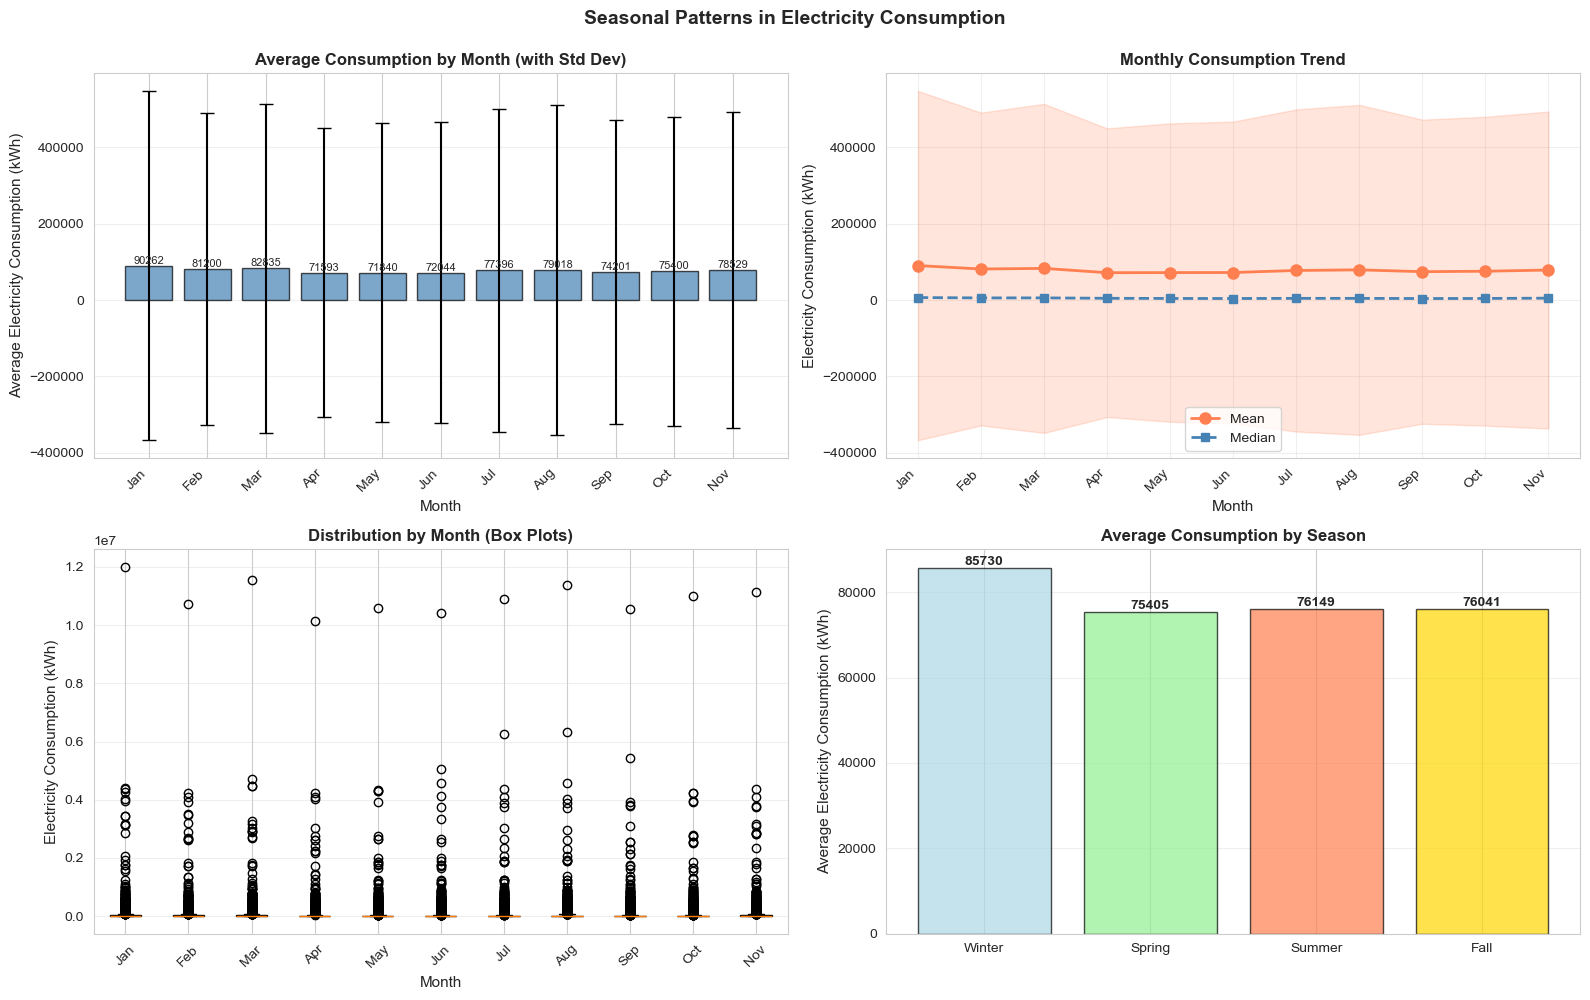


Note: We can see seasonal patterns - typically higher in summer (cooling) and winter (heating).



In [21]:
# EDA 2: Consumption by month (seasonal patterns)
print("=" * 80)
print("SEASONAL PATTERNS ANALYSIS")
print("=" * 80)

monthly_avg = merged_data.groupby('Month')['Usage/Quantity'].mean()
monthly_std = merged_data.groupby('Month')['Usage/Quantity'].std()
monthly_median = merged_data.groupby('Month')['Usage/Quantity'].median()

print("\nAverage consumption by month:")
for month, avg in monthly_avg.items():
    month_name = pd.to_datetime(f'2022-{int(month)}-01').strftime('%B')
    print(f"{month_name:12s}: {avg:10.2f} kWh")

# Comprehensive visualization using matplotlib.pyplot
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Plot 1: Bar chart with error bars
month_names = [pd.to_datetime(f'2022-{int(i)}-01').strftime('%b') for i in monthly_avg.index]
x_pos = np.arange(len(month_names))
bars = axes[0, 0].bar(x_pos, monthly_avg.values, yerr=monthly_std.values, 
                       color='steelblue', edgecolor='black', alpha=0.7, capsize=5)
axes[0, 0].set_xlabel('Month', fontsize=11)
axes[0, 0].set_ylabel('Average Electricity Consumption (kWh)', fontsize=11)
axes[0, 0].set_title('Average Consumption by Month (with Std Dev)', fontsize=12, fontweight='bold')
axes[0, 0].set_xticks(x_pos)
axes[0, 0].set_xticklabels(month_names, rotation=45, ha='right')
axes[0, 0].grid(axis='y', alpha=0.3)
# Add value labels on bars
for i, (bar, avg) in enumerate(zip(bars, monthly_avg.values)):
    height = bar.get_height()
    axes[0, 0].text(bar.get_x() + bar.get_width()/2., height,
                    f'{avg:.0f}', ha='center', va='bottom', fontsize=8)

# Plot 2: Line plot showing trend
axes[0, 1].plot(month_names, monthly_avg.values, marker='o', linewidth=2, 
                markersize=8, color='coral', label='Mean')
axes[0, 1].plot(month_names, monthly_median.values, marker='s', linewidth=2, 
                markersize=6, color='steelblue', label='Median', linestyle='--')
axes[0, 1].fill_between(month_names, monthly_avg.values - monthly_std.values,
                        monthly_avg.values + monthly_std.values, alpha=0.2, color='coral')
axes[0, 1].set_xlabel('Month', fontsize=11)
axes[0, 1].set_ylabel('Electricity Consumption (kWh)', fontsize=11)
axes[0, 1].set_title('Monthly Consumption Trend', fontsize=12, fontweight='bold')
axes[0, 1].set_xticklabels(month_names, rotation=45, ha='right')
axes[0, 1].legend(fontsize=10)
axes[0, 1].grid(alpha=0.3)

# Plot 3: Box plots by month
monthly_data = [merged_data[merged_data['Month'] == month]['Usage/Quantity'].values 
                for month in monthly_avg.index]
bp = axes[1, 0].boxplot(monthly_data, labels=month_names, patch_artist=True)
for patch in bp['boxes']:
    patch.set_facecolor('lightgreen')
    patch.set_edgecolor('black')
axes[1, 0].set_xlabel('Month', fontsize=11)
axes[1, 0].set_ylabel('Electricity Consumption (kWh)', fontsize=11)
axes[1, 0].set_title('Distribution by Month (Box Plots)', fontsize=12, fontweight='bold')
axes[1, 0].tick_params(axis='x', rotation=45)
axes[1, 0].grid(axis='y', alpha=0.3)

# Plot 4: Seasonal comparison (grouped by season)
if 'Season' in merged_data.columns:
    seasonal_avg = merged_data.groupby('Season')['Usage/Quantity'].mean()
    season_names = ['Winter', 'Spring', 'Summer', 'Fall']
    colors_season = ['lightblue', 'lightgreen', 'coral', 'gold']
    bars = axes[1, 1].bar(season_names, seasonal_avg.values, 
                          color=colors_season, edgecolor='black', alpha=0.7)
    axes[1, 1].set_ylabel('Average Electricity Consumption (kWh)', fontsize=11)
    axes[1, 1].set_title('Average Consumption by Season', fontsize=12, fontweight='bold')
    axes[1, 1].grid(axis='y', alpha=0.3)
    # Add value labels
    for bar, avg in zip(bars, seasonal_avg.values):
        height = bar.get_height()
        axes[1, 1].text(bar.get_x() + bar.get_width()/2., height,
                       f'{avg:.0f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.suptitle('Seasonal Patterns in Electricity Consumption', 
             fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

print("\nNote: We can see seasonal patterns - typically higher in summer (cooling) and winter (heating).\n")


CONSUMPTION BY PROPERTY TYPE

Top 10 property types by count:
Property Type - Self-Selected
Other - Public Services            8594
Transportation Terminal/Station    1815
Parking                            1465
Fire Station                       1000
Library                             957
Social/Meeting Hall                 847
Office                              567
Other - Recreation                  539
Wastewater Treatment Plant          517
Police Station                      396
Name: count, dtype: int64

Average consumption by property type (top 10):
Property Type - Self-Selected
Drinking Water Treatment & Distribution    1.140738e+06
Wastewater Treatment Plant                 3.919830e+05
Residential Care Facility                  2.556560e+05
Transportation Terminal/Station            2.377273e+05
Police Station                             8.733007e+04
Office                                     8.677578e+04
Other - Recreation                         5.855310e+04
Indoor Arena

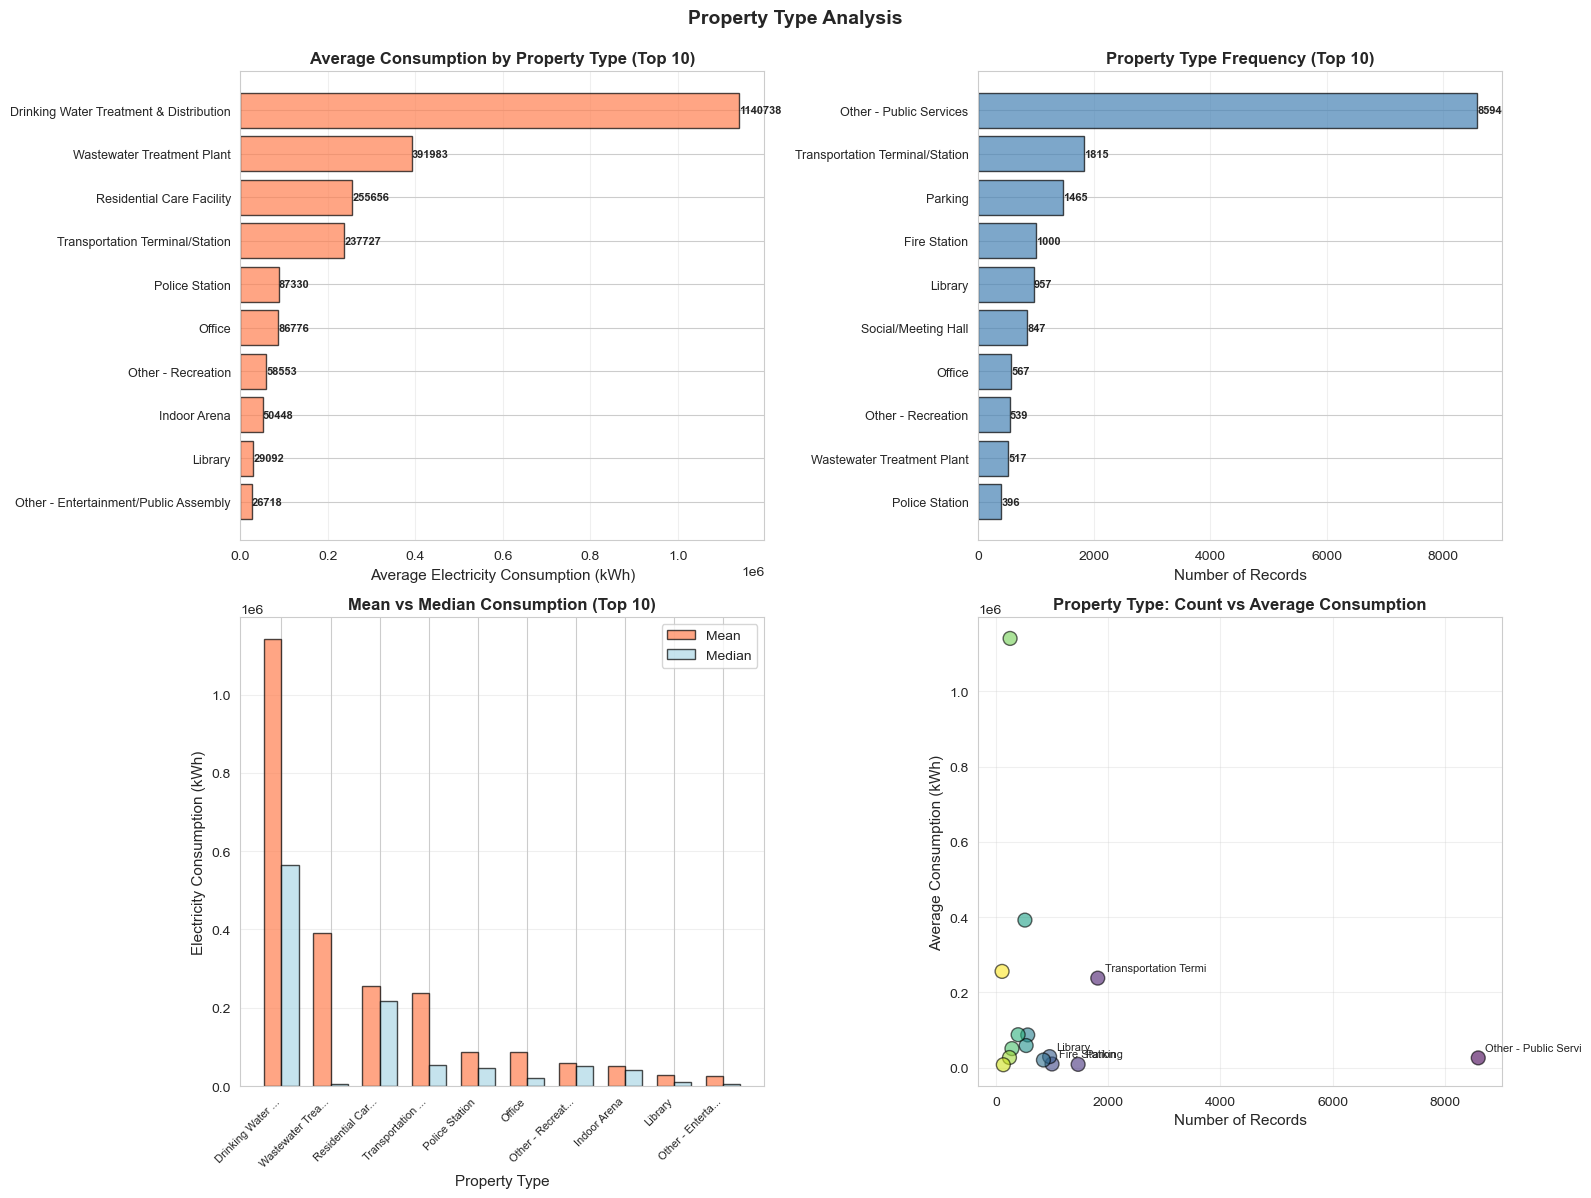


Note: Different property types have different consumption patterns.



In [22]:
# EDA 3: Consumption by property type
print("=" * 80)
print("CONSUMPTION BY PROPERTY TYPE")
print("=" * 80)

# Get top property types by count
top_property_types = merged_data['Property Type - Self-Selected'].value_counts().head(10)
print(f"\nTop 10 property types by count:")
print(top_property_types)

# Calculate average consumption by property type
property_type_avg = merged_data.groupby('Property Type - Self-Selected')['Usage/Quantity'].mean().sort_values(ascending=False)
property_type_median = merged_data.groupby('Property Type - Self-Selected')['Usage/Quantity'].median().sort_values(ascending=False)
property_type_count = merged_data['Property Type - Self-Selected'].value_counts()

print(f"\nAverage consumption by property type (top 10):")
print(property_type_avg.head(10))

# Comprehensive visualization using matplotlib.pyplot
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot 1: Average consumption by property type (top 10)
top_10_avg = property_type_avg.head(10)
y_pos = np.arange(len(top_10_avg))
bars = axes[0, 0].barh(y_pos, top_10_avg.values, color='coral', edgecolor='black', alpha=0.7)
axes[0, 0].set_yticks(y_pos)
axes[0, 0].set_yticklabels(top_10_avg.index, fontsize=9)
axes[0, 0].set_xlabel('Average Electricity Consumption (kWh)', fontsize=11)
axes[0, 0].set_title('Average Consumption by Property Type (Top 10)', fontsize=12, fontweight='bold')
axes[0, 0].grid(axis='x', alpha=0.3)
axes[0, 0].invert_yaxis()
# Add value labels
for i, (bar, val) in enumerate(zip(bars, top_10_avg.values)):
    axes[0, 0].text(val, bar.get_y() + bar.get_height()/2,
                   f'{val:.0f}', va='center', ha='left', fontsize=8, fontweight='bold')

# Plot 2: Property type counts (top 10)
top_10_count = property_type_count.head(10)
y_pos2 = np.arange(len(top_10_count))
bars2 = axes[0, 1].barh(y_pos2, top_10_count.values, color='steelblue', edgecolor='black', alpha=0.7)
axes[0, 1].set_yticks(y_pos2)
axes[0, 1].set_yticklabels(top_10_count.index, fontsize=9)
axes[0, 1].set_xlabel('Number of Records', fontsize=11)
axes[0, 1].set_title('Property Type Frequency (Top 10)', fontsize=12, fontweight='bold')
axes[0, 1].grid(axis='x', alpha=0.3)
axes[0, 1].invert_yaxis()
# Add value labels
for i, (bar, val) in enumerate(zip(bars2, top_10_count.values)):
    axes[0, 1].text(val, bar.get_y() + bar.get_height()/2,
                   f'{val}', va='center', ha='left', fontsize=8, fontweight='bold')

# Plot 3: Comparison of mean vs median (top 10)
top_10_types = property_type_avg.head(10).index
x_pos = np.arange(len(top_10_types))
width = 0.35
means = [property_type_avg[pt] for pt in top_10_types]
medians = [property_type_median[pt] for pt in top_10_types]
axes[1, 0].bar(x_pos - width/2, means, width, label='Mean', color='coral', edgecolor='black', alpha=0.7)
axes[1, 0].bar(x_pos + width/2, medians, width, label='Median', color='lightblue', edgecolor='black', alpha=0.7)
axes[1, 0].set_xlabel('Property Type', fontsize=11)
axes[1, 0].set_ylabel('Electricity Consumption (kWh)', fontsize=11)
axes[1, 0].set_title('Mean vs Median Consumption (Top 10)', fontsize=12, fontweight='bold')
axes[1, 0].set_xticks(x_pos)
axes[1, 0].set_xticklabels([pt[:15] + '...' if len(pt) > 15 else pt for pt in top_10_types], 
                           rotation=45, ha='right', fontsize=8)
axes[1, 0].legend(fontsize=10)
axes[1, 0].grid(axis='y', alpha=0.3)

# Plot 4: Scatter plot: Count vs Average Consumption
top_15_types = property_type_count.head(15).index
counts = [property_type_count[pt] for pt in top_15_types]
avgs = [property_type_avg[pt] for pt in top_15_types]
scatter = axes[1, 1].scatter(counts, avgs, s=100, alpha=0.6, c=range(len(top_15_types)), 
                             cmap='viridis', edgecolors='black', linewidth=1)
axes[1, 1].set_xlabel('Number of Records', fontsize=11)
axes[1, 1].set_ylabel('Average Consumption (kWh)', fontsize=11)
axes[1, 1].set_title('Property Type: Count vs Average Consumption', fontsize=12, fontweight='bold')
axes[1, 1].grid(alpha=0.3)
# Add labels for top 5
for i, pt in enumerate(top_15_types[:5]):
    axes[1, 1].annotate(pt[:20], (counts[i], avgs[i]), 
                        xytext=(5, 5), textcoords='offset points', fontsize=8)

plt.suptitle('Property Type Analysis', fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

print("\nNote: Different property types have different consumption patterns.\n")


FLOOR AREA vs CONSUMPTION ANALYSIS

Correlation between Gross Floor Area and Consumption: 0.334


C:\Users\julia\AppData\Local\Temp\ipykernel_12944\1826164225.py:51: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bin_avg = valid_floor_area.groupby('Floor_Area_Bin')['Usage/Quantity'].mean()


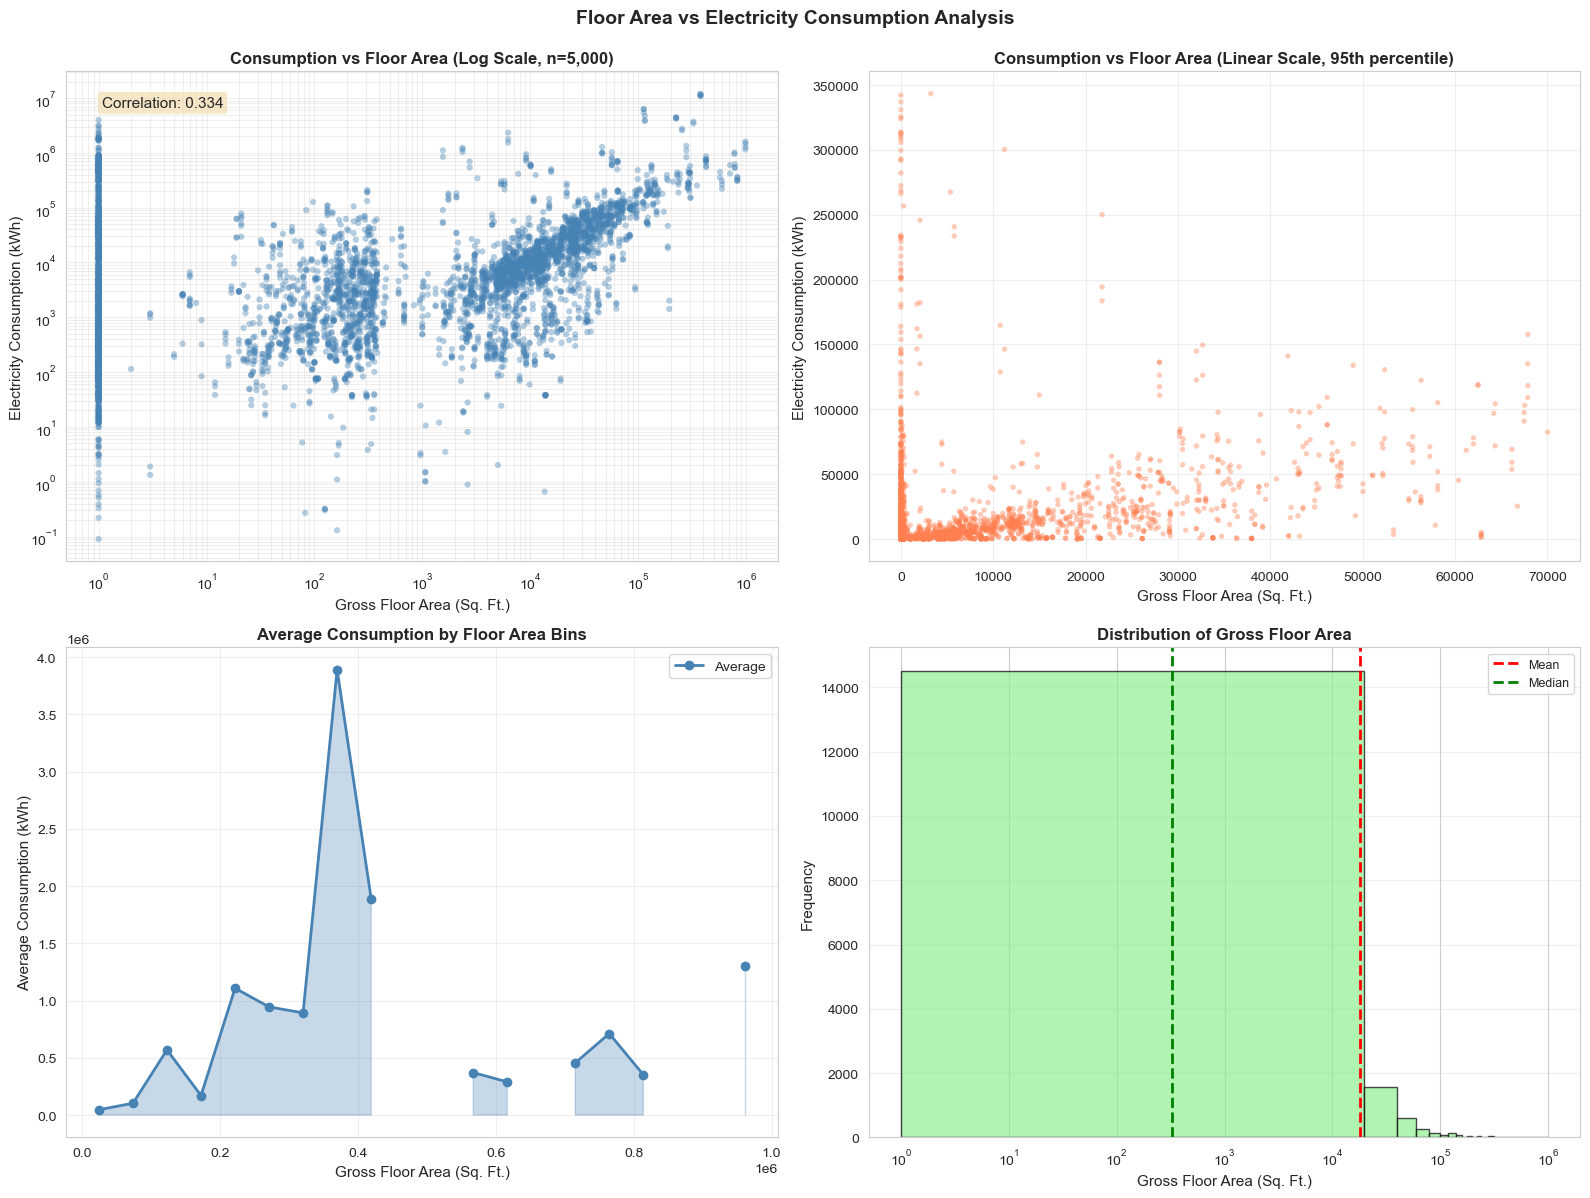


Note: Strong positive correlation - larger buildings consume more electricity.



In [23]:
# EDA 4: Relationship between floor area and consumption
print("=" * 80)
print("FLOOR AREA vs CONSUMPTION ANALYSIS")
print("=" * 80)

# Filter out rows with valid floor area
valid_floor_area = merged_data[merged_data['Gross Floor Area'] > 0].copy()

if len(valid_floor_area) > 0:
    correlation = valid_floor_area['Gross Floor Area'].corr(valid_floor_area['Usage/Quantity'])
    print(f"\nCorrelation between Gross Floor Area and Consumption: {correlation:.3f}")
    
    # Comprehensive visualization using matplotlib.pyplot
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    
    # Plot 1: Scatter plot (log scale)
    sample_size = min(5000, len(valid_floor_area))
    sample_data = valid_floor_area.sample(sample_size, random_state=42)
    scatter = axes[0, 0].scatter(sample_data['Gross Floor Area'], sample_data['Usage/Quantity'], 
                                 alpha=0.4, s=20, c='steelblue', edgecolors='none')
    axes[0, 0].set_xlabel('Gross Floor Area (Sq. Ft.)', fontsize=11)
    axes[0, 0].set_ylabel('Electricity Consumption (kWh)', fontsize=11)
    axes[0, 0].set_title(f'Consumption vs Floor Area (Log Scale, n={sample_size:,})', 
                        fontsize=12, fontweight='bold')
    axes[0, 0].set_xscale('log')
    axes[0, 0].set_yscale('log')
    axes[0, 0].grid(alpha=0.3, which='both')
    
    # Add correlation text
    axes[0, 0].text(0.05, 0.95, f'Correlation: {correlation:.3f}', 
                   transform=axes[0, 0].transAxes, fontsize=11,
                   verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.7))
    
    # Plot 2: Scatter plot (linear scale) - zoomed in
    # Filter to reasonable range for better visualization
    reasonable_range = valid_floor_area[
        (valid_floor_area['Gross Floor Area'] <= valid_floor_area['Gross Floor Area'].quantile(0.95)) &
        (valid_floor_area['Usage/Quantity'] <= valid_floor_area['Usage/Quantity'].quantile(0.95))
    ]
    sample_reasonable = reasonable_range.sample(min(3000, len(reasonable_range)), random_state=42)
    axes[0, 1].scatter(sample_reasonable['Gross Floor Area'], sample_reasonable['Usage/Quantity'], 
                       alpha=0.4, s=15, c='coral', edgecolors='none')
    axes[0, 1].set_xlabel('Gross Floor Area (Sq. Ft.)', fontsize=11)
    axes[0, 1].set_ylabel('Electricity Consumption (kWh)', fontsize=11)
    axes[0, 1].set_title('Consumption vs Floor Area (Linear Scale, 95th percentile)', 
                        fontsize=12, fontweight='bold')
    axes[0, 1].grid(alpha=0.3)
    
    # Plot 3: Binned average consumption by floor area ranges
    valid_floor_area['Floor_Area_Bin'] = pd.cut(valid_floor_area['Gross Floor Area'], bins=20)
    bin_avg = valid_floor_area.groupby('Floor_Area_Bin')['Usage/Quantity'].mean()
    bin_centers = [interval.mid for interval in bin_avg.index]
    axes[1, 0].plot(bin_centers, bin_avg.values, marker='o', linewidth=2, 
                   markersize=6, color='steelblue', label='Average')
    axes[1, 0].fill_between(bin_centers, bin_avg.values, alpha=0.3, color='steelblue')
    axes[1, 0].set_xlabel('Gross Floor Area (Sq. Ft.)', fontsize=11)
    axes[1, 0].set_ylabel('Average Consumption (kWh)', fontsize=11)
    axes[1, 0].set_title('Average Consumption by Floor Area Bins', fontsize=12, fontweight='bold')
    axes[1, 0].grid(alpha=0.3)
    axes[1, 0].legend(fontsize=10)
    
    # Plot 4: Distribution of floor areas
    axes[1, 1].hist(valid_floor_area['Gross Floor Area'], bins=50, 
                   color='lightgreen', edgecolor='black', alpha=0.7)
    axes[1, 1].set_xlabel('Gross Floor Area (Sq. Ft.)', fontsize=11)
    axes[1, 1].set_ylabel('Frequency', fontsize=11)
    axes[1, 1].set_title('Distribution of Gross Floor Area', fontsize=12, fontweight='bold')
    axes[1, 1].set_xscale('log')
    axes[1, 1].grid(axis='y', alpha=0.3)
    axes[1, 1].axvline(valid_floor_area['Gross Floor Area'].mean(), 
                      color='r', linestyle='--', linewidth=2, label='Mean')
    axes[1, 1].axvline(valid_floor_area['Gross Floor Area'].median(), 
                      color='g', linestyle='--', linewidth=2, label='Median')
    axes[1, 1].legend(fontsize=9)
    
    plt.suptitle('Floor Area vs Electricity Consumption Analysis', 
                fontsize=14, fontweight='bold', y=0.995)
    plt.tight_layout()
    plt.show()
    
    print("\nNote: Strong positive correlation - larger buildings consume more electricity.\n")
else:
    print("No valid floor area data available.\n")


FEATURE CORRELATION ANALYSIS


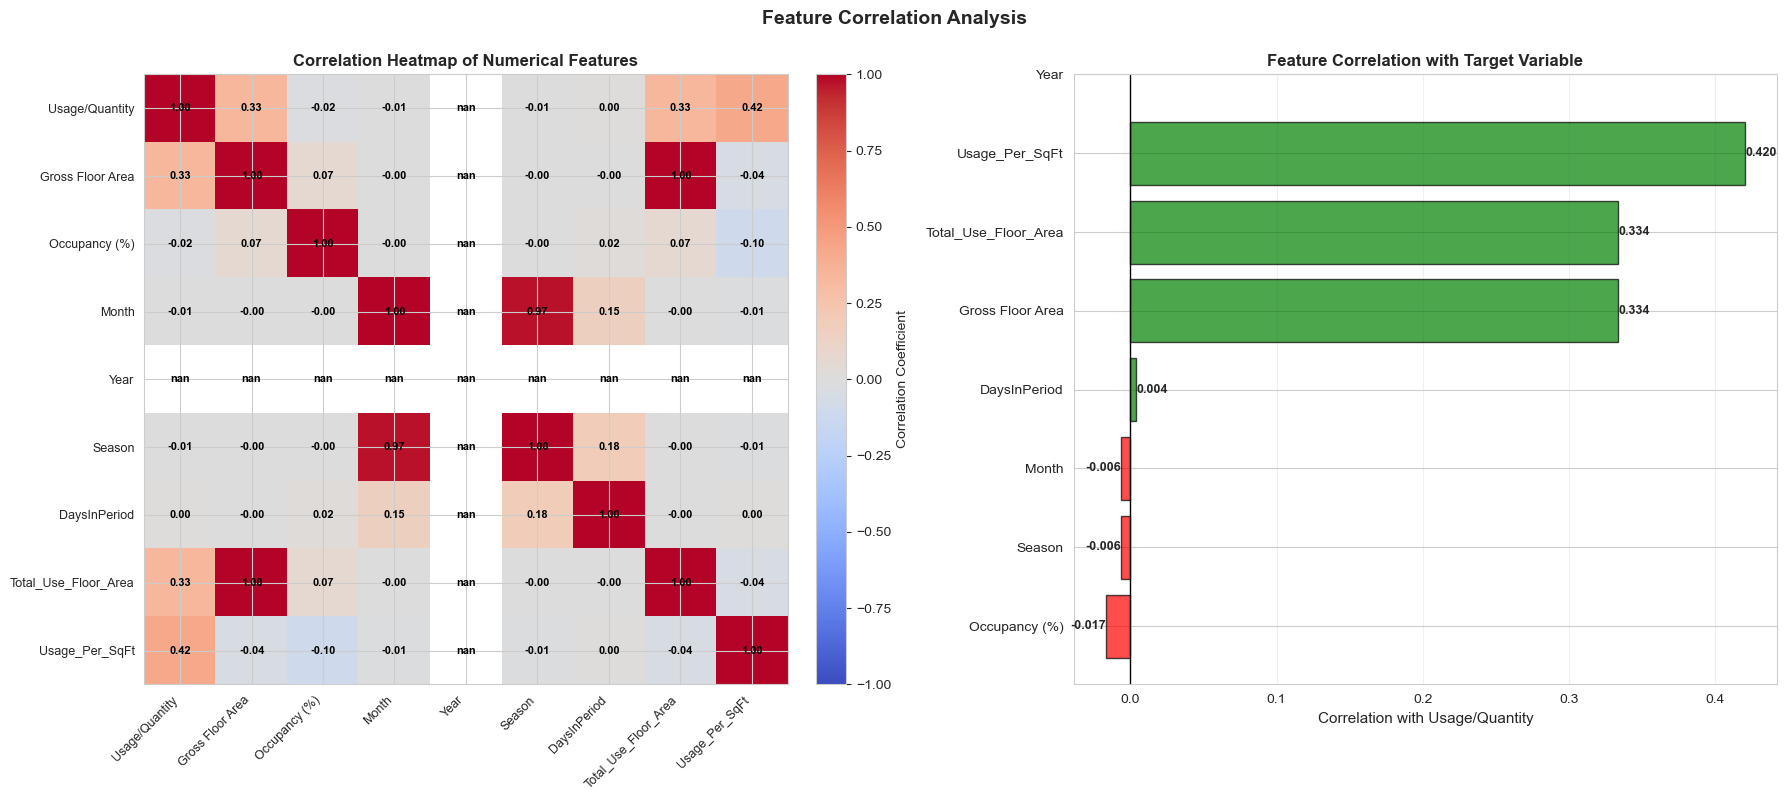


Note: Features with high correlation to 'Usage/Quantity' will be most useful for prediction.

Top correlated features with target:
  Usage_Per_SqFt: 0.420
  Total_Use_Floor_Area: 0.334
  Gross Floor Area: 0.334
  Occupancy (%): -0.017
  Season: -0.006




In [24]:
# EDA 5: Correlation heatmap of numerical features
print("=" * 80)
print("FEATURE CORRELATION ANALYSIS")
print("=" * 80)

# Select numerical features for correlation analysis
numerical_features = [
    'Usage/Quantity',  # Target variable
    'Gross Floor Area',
    'Occupancy (%)',
    'Month',
    'Year',
    'Season',
    'DaysInPeriod',
    'Total_Use_Floor_Area',
    'Usage_Per_SqFt'
]

# Filter to features that exist in the dataset
available_features = [f for f in numerical_features if f in merged_data.columns]

# Calculate correlation matrix
corr_matrix = merged_data[available_features].corr()

# Comprehensive visualization using matplotlib.pyplot
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# Plot 1: Correlation heatmap using matplotlib
im = axes[0].imshow(corr_matrix.values, cmap='coolwarm', aspect='auto', vmin=-1, vmax=1)
axes[0].set_xticks(range(len(corr_matrix.columns)))
axes[0].set_yticks(range(len(corr_matrix.columns)))
axes[0].set_xticklabels(corr_matrix.columns, rotation=45, ha='right', fontsize=9)
axes[0].set_yticklabels(corr_matrix.columns, fontsize=9)
axes[0].set_title('Correlation Heatmap of Numerical Features', fontsize=12, fontweight='bold')

# Add correlation values as text
for i in range(len(corr_matrix.columns)):
    for j in range(len(corr_matrix.columns)):
        text = axes[0].text(j, i, f'{corr_matrix.iloc[i, j]:.2f}',
                           ha="center", va="center", color="black", fontsize=8, fontweight='bold')

# Add colorbar
cbar = plt.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)
cbar.set_label('Correlation Coefficient', fontsize=10)

# Plot 2: Correlation with target variable (bar chart)
target_corr = corr_matrix['Usage/Quantity'].drop('Usage/Quantity').sort_values(ascending=True)
colors_corr = ['red' if x < 0 else 'green' for x in target_corr.values]
bars = axes[1].barh(range(len(target_corr)), target_corr.values, color=colors_corr, 
                    edgecolor='black', alpha=0.7)
axes[1].set_yticks(range(len(target_corr)))
axes[1].set_yticklabels(target_corr.index, fontsize=10)
axes[1].set_xlabel('Correlation with Usage/Quantity', fontsize=11)
axes[1].set_title('Feature Correlation with Target Variable', fontsize=12, fontweight='bold')
axes[1].axvline(0, color='black', linestyle='-', linewidth=1)
axes[1].grid(axis='x', alpha=0.3)
# Add value labels
for i, (bar, val) in enumerate(zip(bars, target_corr.values)):
    axes[1].text(val, bar.get_y() + bar.get_height()/2,
                f'{val:.3f}', va='center', 
                ha='left' if val > 0 else 'right', fontsize=9, fontweight='bold')

plt.suptitle('Feature Correlation Analysis', fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

print("\nNote: Features with high correlation to 'Usage/Quantity' will be most useful for prediction.\n")
print("Top correlated features with target:")
top_corr = corr_matrix['Usage/Quantity'].drop('Usage/Quantity').abs().sort_values(ascending=False)
for feature, corr_val in top_corr.head(5).items():
    print(f"  {feature}: {corr_matrix.loc[feature, 'Usage/Quantity']:.3f}")
print("\n")


## 8. Prepare Data for Modeling

Now we'll prepare the final dataset for machine learning by:
1. Selecting features
2. Encoding categorical variables
3. Handling remaining missing values
4. Splitting into train and test sets

In [25]:
# STEP 1: Define target variable
target = 'Usage/Quantity'
y = merged_data[target].copy()

print(f"Target variable: {target}")
print(f"Target shape: {y.shape}")
print(f"Target statistics:")
print(y.describe())
print("\n")


Target variable: Usage/Quantity
Target shape: (17720,)
Target statistics:
count    1.772000e+04
mean     7.764462e+04
std      4.126198e+05
min      1.000000e-02
25%      6.150475e+02
50%      4.630765e+03
75%      2.530980e+04
max      1.199675e+07
Name: Usage/Quantity, dtype: float64




In [26]:
# STEP 2: Select features for modeling
# We'll use a combination of numerical and categorical features

# Numerical features
numerical_features = [
    'Gross Floor Area',
    'Occupancy (%)',
    'Month',
    'Year',
    'Season',
    'DaysInPeriod',
    'Total_Use_Floor_Area',
    'Has_Floor_Area',
    'Has_Property_Type',
    'Has_Cost'
]

# Add use type floor areas
use_type_features = [col for col in merged_data.columns if col.startswith('Floor_Area_')]

# Categorical features (will be encoded)
categorical_features = ['Property Type - Self-Selected']

# Combine all feature lists
all_features = numerical_features + use_type_features + categorical_features

# Filter to features that actually exist in the dataset
available_features = [f for f in all_features if f in merged_data.columns]

print(f"Selected {len(available_features)} features for modeling")
print(f"Numerical features: {len([f for f in numerical_features if f in merged_data.columns])}")
print(f"Use type features: {len(use_type_features)}")
print(f"Categorical features: {len([f for f in categorical_features if f in merged_data.columns])}")
print("\n")


Selected 26 features for modeling
Numerical features: 10
Use type features: 15
Categorical features: 1




In [27]:
# STEP 3: Create feature matrix X
X = merged_data[available_features].copy()

print(f"Feature matrix shape: {X.shape}")
print(f"\nMissing values in features:")
missing = X.isnull().sum()
print(missing[missing > 0])

# Fill any remaining missing values
# For numerical features, use median
# For categorical features, use mode
for col in X.columns:
    if X[col].dtype in ['int64', 'float64']:
        X[col] = X[col].fillna(X[col].median())
    else:
        X[col] = X[col].fillna(X[col].mode()[0] if len(X[col].mode()) > 0 else 'Unknown')

print(f"\nAfter filling missing values:")
print(f"Remaining missing values: {X.isnull().sum().sum()}")
print("\n")

Feature matrix shape: (17720, 26)

Missing values in features:
Series([], dtype: int64)

After filling missing values:
Remaining missing values: 0




In [28]:
# STEP 4: Encode categorical variables
# Use LabelEncoder for property type (or one-hot encoding for better results)
print("Encoding categorical variables...")

# For property type, we'll use label encoding (can also use one-hot, but label is simpler)
if 'Property Type - Self-Selected' in X.columns:
    le_property_type = LabelEncoder()
    X['Property Type - Self-Selected'] = le_property_type.fit_transform(
        X['Property Type - Self-Selected'].astype(str)
    )
    print(f"Encoded Property Type - {len(le_property_type.classes_)} unique values")

# Ensure all columns are numeric
X = X.apply(pd.to_numeric, errors='coerce')
X = X.fillna(0)  # Fill any conversion errors with 0

print(f"\nFinal feature matrix shape: {X.shape}")
print(f"Feature matrix data types:\n{X.dtypes.value_counts()}")
print("\n")

Encoding categorical variables...
Encoded Property Type - 15 unique values

Final feature matrix shape: (17720, 26)
Feature matrix data types:
float64    16
int64       8
int32       2
Name: count, dtype: int64




In [29]:
# STEP 5: Split data into training and testing sets
# Use 80% for training and 20% for testing
# Set random_state for reproducibility
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42
)

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Test set size: {X_test.shape[0]} samples")
print(f"Number of features: {X_train.shape[1]}")
print("\n")

# STEP 6: Scale features (important for some algorithms)
# StandardScaler standardizes features by removing mean and scaling to unit variance
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert back to DataFrame for easier handling
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X.columns, index=X_test.index)

print("Features scaled using StandardScaler")
print("Ready for modeling!")
print("\n")

Training set size: 14176 samples
Test set size: 3544 samples
Number of features: 26


Features scaled using StandardScaler
Ready for modeling!




## 9. Model Building

We'll build and compare multiple models:
1. **Linear Regression** - Baseline model, interpretable
2. **Random Forest Regressor** - Handles non-linear relationships, feature importance
3. **Gradient Boosting Regressor** - Often performs well on structured data

We'll evaluate each model using appropriate metrics.

In [30]:
# Define a function to evaluate models
# This will help us compare models consistently
def evaluate_model(model, X_train, X_test, y_train, y_test, model_name):
    """
    Evaluate a regression model and return metrics.
    
    Parameters:
    - model: The trained model
    - X_train, X_test: Training and test feature sets
    - y_train, y_test: Training and test target values
    - model_name: Name of the model for display
    
    Returns:
    - Dictionary with evaluation metrics
    """
    # Make predictions
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    
    # Calculate metrics
    train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
    
    train_mae = mean_absolute_error(y_train, y_train_pred)
    test_mae = mean_absolute_error(y_test, y_test_pred)
    
    train_r2 = r2_score(y_train, y_train_pred)
    test_r2 = r2_score(y_test, y_test_pred)
    
    # Print results
    print(f"\n{'='*60}")
    print(f"{model_name} - Evaluation Results")
    print(f"{'='*60}")
    print(f"Training RMSE: {train_rmse:.2f} kWh")
    print(f"Test RMSE:     {test_rmse:.2f} kWh")
    print(f"Training MAE:  {train_mae:.2f} kWh")
    print(f"Test MAE:      {test_mae:.2f} kWh")
    print(f"Training R²:   {train_r2:.4f}")
    print(f"Test R²:       {test_r2:.4f}")
    print(f"{'='*60}\n")
    
    return {
        'model_name': model_name,
        'train_rmse': train_rmse,
        'test_rmse': test_rmse,
        'train_mae': train_mae,
        'test_mae': test_mae,
        'train_r2': train_r2,
        'test_r2': test_r2,
        'y_test_pred': y_test_pred
    }

print("Evaluation function defined!")
print("\n")


Evaluation function defined!




### Model 1: Linear Regression

Linear Regression is a simple baseline model that assumes a linear relationship between features and target.

In [31]:
# MODEL 1: Linear Regression
# Linear regression assumes a linear relationship: y = β₀ + β₁x₁ + β₂x₂ + ...
# It's fast, interpretable, and serves as a good baseline

print("Training Linear Regression model...")

# Create and train the model
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

# Evaluate the model
lr_results = evaluate_model(
    lr_model, 
    X_train_scaled, 
    X_test_scaled, 
    y_train, 
    y_test, 
    "Linear Regression"
)

# Store results for later comparison
model_results = [lr_results]


Training Linear Regression model...

Linear Regression - Evaluation Results
Training RMSE: 239897.77 kWh
Test RMSE:     250127.82 kWh
Training MAE:  76276.44 kWh
Test MAE:      74486.21 kWh
Training R²:   0.6579
Test R²:       0.6492



### Model 2: Random Forest Regressor

Random Forest is an ensemble method that builds multiple decision trees and averages their predictions. It can capture non-linear relationships and provides feature importance.

In [32]:
# MODEL 2: Random Forest Regressor
# Random Forest builds multiple decision trees and averages their predictions
# It can handle non-linear relationships and provides feature importance
# n_estimators: number of trees (more trees = better but slower)
# max_depth: maximum depth of trees (prevents overfitting)
# random_state: for reproducibility

print("Training Random Forest Regressor model...")

# Create and train the model
# We'll use default parameters first, then can tune if needed
rf_model = RandomForestRegressor(
    n_estimators=100,      # Number of trees
    max_depth=20,          # Maximum depth of trees
    min_samples_split=5,   # Minimum samples required to split a node
    min_samples_leaf=2,    # Minimum samples required in a leaf node
    random_state=42,
    n_jobs=-1              # Use all available CPU cores
)

rf_model.fit(X_train_scaled, y_train)

# Evaluate the model
rf_results = evaluate_model(
    rf_model, 
    X_train_scaled, 
    X_test_scaled, 
    y_train, 
    y_test, 
    "Random Forest Regressor"
)

# Store results
model_results.append(rf_results)

Training Random Forest Regressor model...

Random Forest Regressor - Evaluation Results
Training RMSE: 172509.09 kWh
Test RMSE:     163429.79 kWh
Training MAE:  43538.25 kWh
Test MAE:      44136.23 kWh
Training R²:   0.8231
Test R²:       0.8502



Random Forest - Feature Importance (Top 15)
                                           feature  importance
             Floor_Area_Wastewater_Treatment_Plant    0.588495
Floor_Area_Drinking_Water_Treatment_&_Distribution    0.311805
                     Property Type - Self-Selected    0.031484
                                  Gross Floor Area    0.025014
                              Total_Use_Floor_Area    0.024767
                                             Month    0.005569
                                     Occupancy (%)    0.004314
                Floor_Area_Other_-_Public_Services    0.002125
        Floor_Area_Transportation_Terminal_Station    0.001814
                                      DaysInPeriod    0.001591
                                            Season    0.001223
              Floor_Area_Residential_Care_Facility    0.000351
                         Floor_Area_Police_Station    0.000350
                                 Floor_Area_Office    0.000312
  Floor_Are

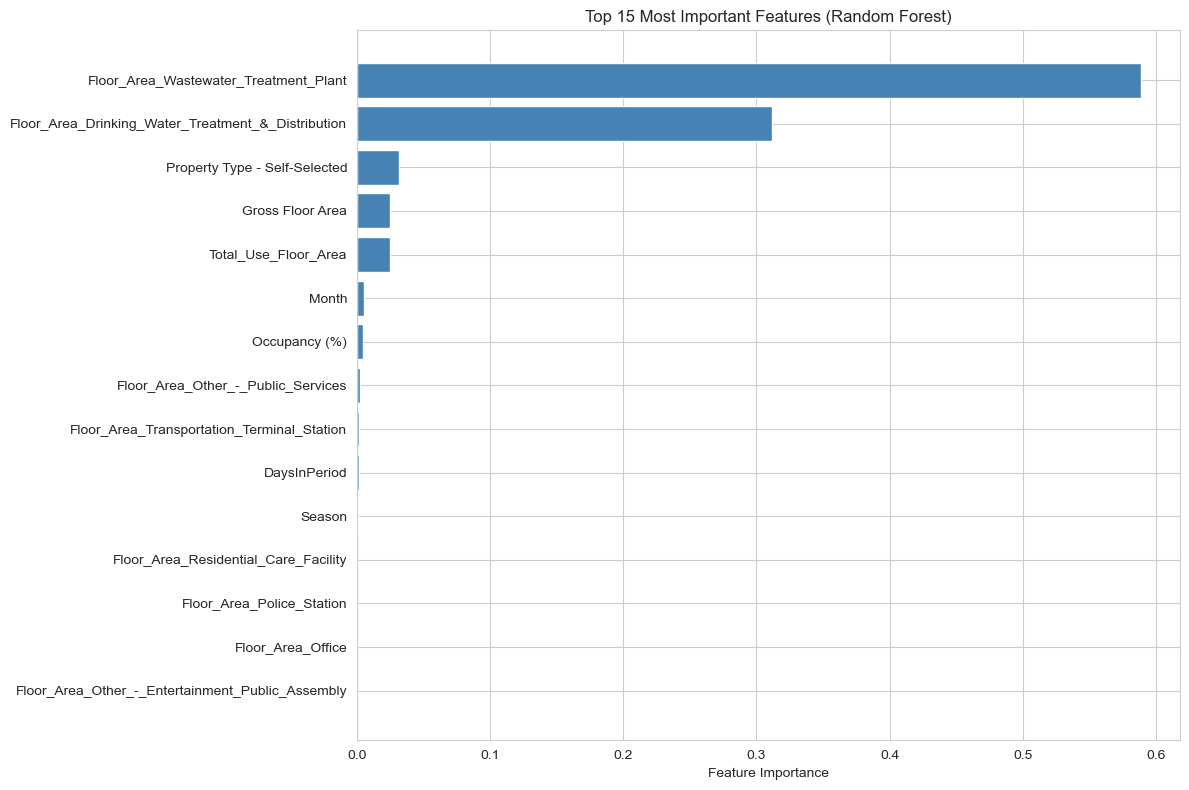


Note: Features with higher importance contribute more to predictions.



In [33]:
# Display feature importance from Random Forest
# This tells us which features are most important for prediction
print("=" * 60)
print("Random Forest - Feature Importance (Top 15)")
print("=" * 60)

feature_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': rf_model.feature_importances_
}).sort_values('importance', ascending=False)

print(feature_importance.head(15).to_string(index=False))

# Visualization
plt.figure(figsize=(12, 8))
top_features = feature_importance.head(15)
plt.barh(range(len(top_features)), top_features['importance'], color='steelblue')
plt.yticks(range(len(top_features)), top_features['feature'])
plt.xlabel('Feature Importance')
plt.title('Top 15 Most Important Features (Random Forest)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print("\nNote: Features with higher importance contribute more to predictions.\n")


### Model 3: Gradient Boosting Regressor

Gradient Boosting builds trees sequentially, where each tree corrects the errors of the previous ones. It often achieves high performance.


In [34]:
# MODEL 3: Gradient Boosting Regressor
# Gradient Boosting builds trees sequentially, each correcting previous errors
# learning_rate: step size (lower = more conservative, requires more trees)
# n_estimators: number of boosting stages
# max_depth: maximum depth of trees

print("Training Gradient Boosting Regressor model...")

# Create and train the model
gb_model = GradientBoostingRegressor(
    n_estimators=100,      # Number of boosting stages
    learning_rate=0.1,      # Step size shrinkage
    max_depth=10,           # Maximum depth of trees
    min_samples_split=5,   # Minimum samples to split
    min_samples_leaf=2,     # Minimum samples in leaf
    random_state=42
)

gb_model.fit(X_train_scaled, y_train)

# Evaluate the model
gb_results = evaluate_model(
    gb_model, 
    X_train_scaled, 
    X_test_scaled, 
    y_train, 
    y_test, 
    "Gradient Boosting Regressor"
)

# Store results
model_results.append(gb_results)

Training Gradient Boosting Regressor model...

Gradient Boosting Regressor - Evaluation Results
Training RMSE: 170779.62 kWh
Test RMSE:     161048.09 kWh
Training MAE:  43010.02 kWh
Test MAE:      44115.60 kWh
Training R²:   0.8266
Test R²:       0.8546



## 10. Model Comparison and Evaluation

Let's compare all models side by side and visualize their performance.

MODEL COMPARISON SUMMARY
                      Model  Test RMSE (kWh)  Test MAE (kWh)  Test R²
Gradient Boosting Regressor    161048.094278    44115.602110 0.854565
    Random Forest Regressor    163429.791839    44136.228174 0.850231
          Linear Regression    250127.818742    74486.213471 0.649182




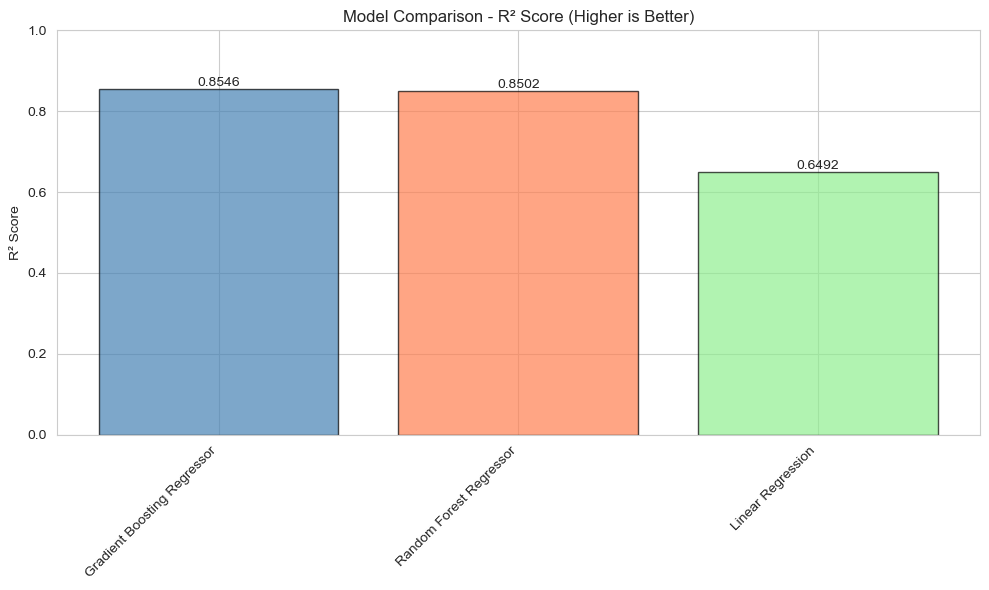


Note: R² score ranges from 0 to 1, where 1 is perfect prediction.



In [35]:
# Compare all models
print("=" * 80)
print("MODEL COMPARISON SUMMARY")
print("=" * 80)

comparison_df = pd.DataFrame(model_results)
comparison_df = comparison_df[['model_name', 'test_rmse', 'test_mae', 'test_r2']]
comparison_df.columns = ['Model', 'Test RMSE (kWh)', 'Test MAE (kWh)', 'Test R²']
comparison_df = comparison_df.sort_values('Test R²', ascending=False)

print(comparison_df.to_string(index=False))
print("\n")

# Visualization: Compare R² scores
plt.figure(figsize=(10, 6))
models = comparison_df['Model']
r2_scores = comparison_df['Test R²']
colors = ['steelblue', 'coral', 'lightgreen']

bars = plt.bar(models, r2_scores, color=colors[:len(models)], edgecolor='black', alpha=0.7)
plt.ylabel('R² Score')
plt.title('Model Comparison - R² Score (Higher is Better)')
plt.ylim([0, 1])
plt.xticks(rotation=45, ha='right')

# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.4f}',
             ha='center', va='bottom')

plt.tight_layout()
plt.show()

print("\nNote: R² score ranges from 0 to 1, where 1 is perfect prediction.\n")


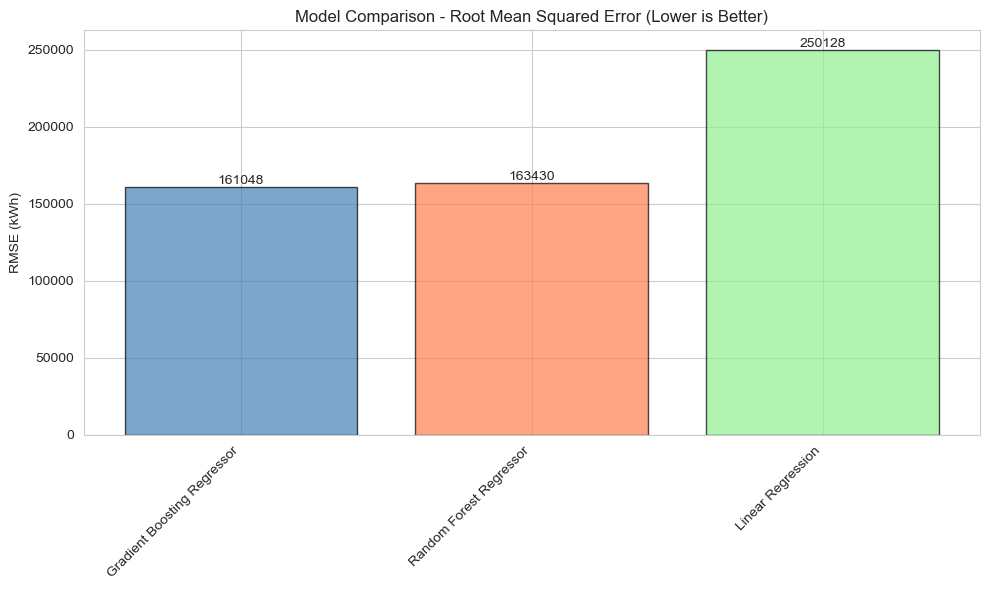


Note: RMSE measures average prediction error in kWh.



In [36]:
# Visualization: Compare RMSE scores
plt.figure(figsize=(10, 6))
rmse_scores = comparison_df['Test RMSE (kWh)']
colors = ['steelblue', 'coral', 'lightgreen']

bars = plt.bar(models, rmse_scores, color=colors[:len(models)], edgecolor='black', alpha=0.7)
plt.ylabel('RMSE (kWh)')
plt.title('Model Comparison - Root Mean Squared Error (Lower is Better)')
plt.xticks(rotation=45, ha='right')

# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.0f}',
             ha='center', va='bottom')

plt.tight_layout()
plt.show()

print("\nNote: RMSE measures average prediction error in kWh.\n")

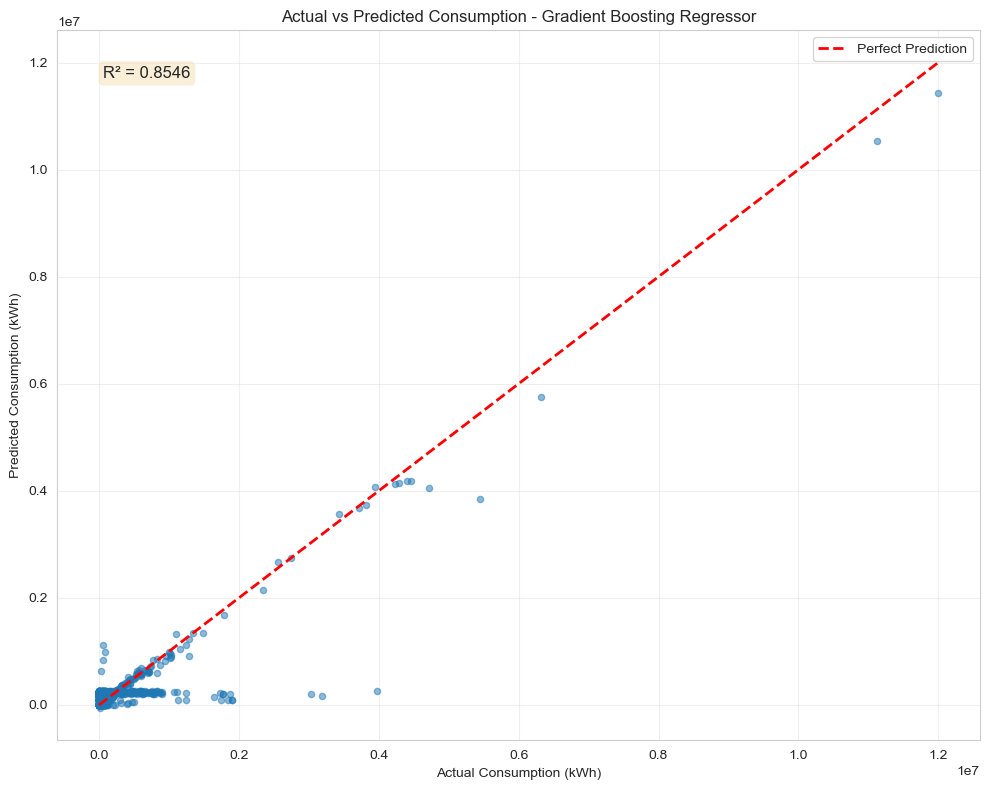


Best model: Gradient Boosting Regressor
Points closer to the red line indicate better predictions.



In [37]:
# Visualization: Actual vs Predicted for the best model
# Find the best model (highest R²)
best_model_idx = comparison_df['Test R²'].idxmax()
best_model_name = comparison_df.loc[best_model_idx, 'Model']

# Get predictions from the best model
if best_model_name == "Linear Regression":
    best_predictions = lr_results['y_test_pred']
elif best_model_name == "Random Forest Regressor":
    best_predictions = rf_results['y_test_pred']
else:
    best_predictions = gb_results['y_test_pred']

# Create scatter plot: Actual vs Predicted
plt.figure(figsize=(10, 8))
plt.scatter(y_test, best_predictions, alpha=0.5, s=20)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Prediction')
plt.xlabel('Actual Consumption (kWh)')
plt.ylabel('Predicted Consumption (kWh)')
plt.title(f'Actual vs Predicted Consumption - {best_model_name}')
plt.legend()
plt.grid(True, alpha=0.3)

# Add R² score to plot
r2_best = comparison_df.loc[best_model_idx, 'Test R²']
plt.text(0.05, 0.95, f'R² = {r2_best:.4f}', 
         transform=plt.gca().transAxes, 
         fontsize=12, 
         verticalalignment='top',
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()

print(f"\nBest model: {best_model_name}")
print(f"Points closer to the red line indicate better predictions.\n")


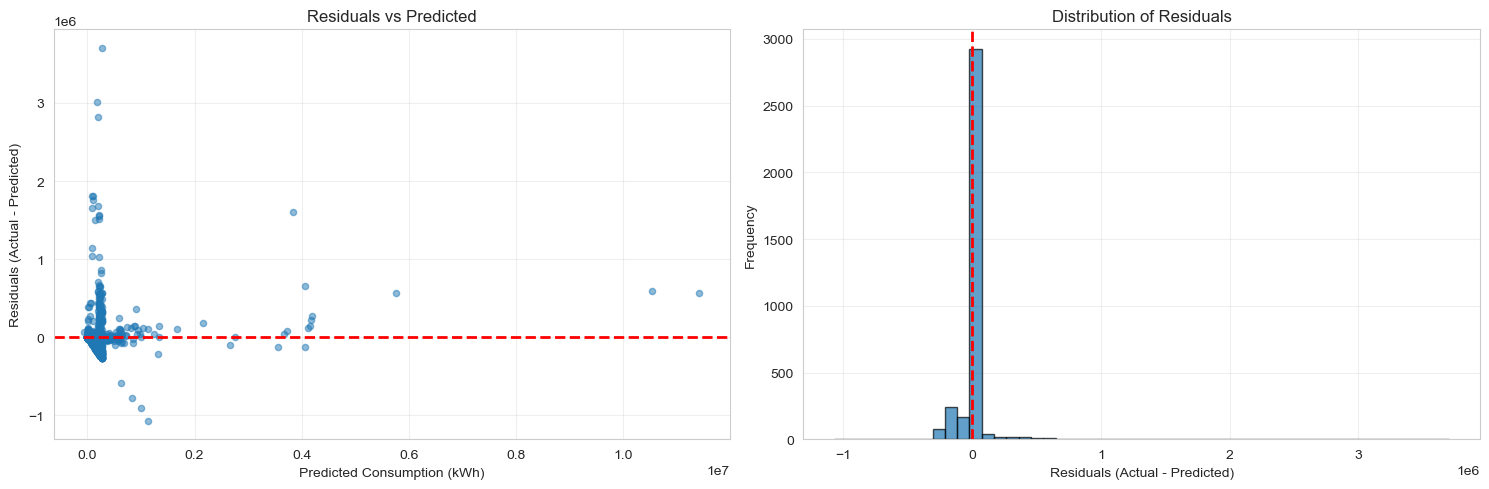


Note: Residuals should be randomly distributed around zero.
Patterns in residuals indicate the model is missing some relationships.



In [38]:
# Visualization: Residuals plot for the best model
# Residuals = Actual - Predicted
# Good models have residuals randomly distributed around zero

residuals = y_test - best_predictions

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Residuals vs Predicted
axes[0].scatter(best_predictions, residuals, alpha=0.5, s=20)
axes[0].axhline(y=0, color='r', linestyle='--', linewidth=2)
axes[0].set_xlabel('Predicted Consumption (kWh)')
axes[0].set_ylabel('Residuals (Actual - Predicted)')
axes[0].set_title('Residuals vs Predicted')
axes[0].grid(True, alpha=0.3)

# Histogram of residuals
axes[1].hist(residuals, bins=50, edgecolor='black', alpha=0.7)
axes[1].axvline(x=0, color='r', linestyle='--', linewidth=2)
axes[1].set_xlabel('Residuals (Actual - Predicted)')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Distribution of Residuals')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nNote: Residuals should be randomly distributed around zero.")
print("Patterns in residuals indicate the model is missing some relationships.\n")


## 11. Insights and Summary

Let's summarize our findings and provide insights.


In [39]:
# Summary statistics and insights
print("=" * 80)
print("KEY INSIGHTS AND FINDINGS")
print("=" * 80)

print("\n1. DATA OVERVIEW:")
print(f"   - Total Electric - Grid meter entries: {len(electric_data):,}")
print(f"   - Number of unique properties: {electric_data['Portfolio Manager ID'].nunique():,}")
print(f"   - Date range: {electric_data['Start Date'].min().date()} to {electric_data['Start Date'].max().date()}")
print(f"   - Average monthly consumption: {y.mean():.2f} kWh")
print(f"   - Median monthly consumption: {y.median():.2f} kWh")

print("\n2. DATA QUALITY:")
print(f"   - Missing values handled: Yes")
print(f"   - Duplicates removed: Yes")
print(f"   - Invalid entries removed: Yes")
print(f"   - Final dataset size: {len(merged_data):,} rows, {len(X.columns)} features")

print("\n3. KEY FEATURES:")
if 'Gross Floor Area' in X.columns:
    floor_area_corr = merged_data['Gross Floor Area'].corr(merged_data['Usage/Quantity'])
    print(f"   - Gross Floor Area correlation with consumption: {floor_area_corr:.3f}")
print(f"   - Temporal features (Month, Season, Year) included")
print(f"   - Property type information included")
print(f"   - Use type floor areas included")

print("\n4. MODEL PERFORMANCE:")
for idx, result in enumerate(model_results, 1):
    print(f"\n   Model {idx}: {result['model_name']}")
    print(f"   - Test R²: {result['test_r2']:.4f}")
    print(f"   - Test RMSE: {result['test_rmse']:.2f} kWh")
    print(f"   - Test MAE: {result['test_mae']:.2f} kWh")

print("\n5. BEST MODEL:")
print(f"   - {best_model_name}")
print(f"   - R² Score: {comparison_df.loc[best_model_idx, 'Test R²']:.4f}")
print(f"   - RMSE: {comparison_df.loc[best_model_idx, 'Test RMSE (kWh)']:.2f} kWh")
print(f"   - MAE: {comparison_df.loc[best_model_idx, 'Test MAE (kWh)']:.2f} kWh")

print("\n6. INTERPRETATION:")
print("   - R² score indicates how well the model explains variance in consumption")
print("   - RMSE shows average prediction error in kWh")
print("   - MAE shows average absolute error")
print("   - Higher R² and lower RMSE/MAE indicate better performance")

print("\n" + "=" * 80)


KEY INSIGHTS AND FINDINGS

1. DATA OVERVIEW:
   - Total Electric - Grid meter entries: 17,720
   - Number of unique properties: 1,632
   - Date range: 2022-01-01 to 2022-11-01
   - Average monthly consumption: 77644.62 kWh
   - Median monthly consumption: 4630.76 kWh

2. DATA QUALITY:
   - Missing values handled: Yes
   - Duplicates removed: Yes
   - Invalid entries removed: Yes
   - Final dataset size: 17,720 rows, 26 features

3. KEY FEATURES:
   - Gross Floor Area correlation with consumption: 0.334
   - Temporal features (Month, Season, Year) included
   - Property type information included
   - Use type floor areas included

4. MODEL PERFORMANCE:

   Model 1: Linear Regression
   - Test R²: 0.6492
   - Test RMSE: 250127.82 kWh
   - Test MAE: 74486.21 kWh

   Model 2: Random Forest Regressor
   - Test R²: 0.8502
   - Test RMSE: 163429.79 kWh
   - Test MAE: 44136.23 kWh

   Model 3: Gradient Boosting Regressor
   - Test R²: 0.8546
   - Test RMSE: 161048.09 kWh
   - Test MAE: 44115.6

## 12. Conclusions

### Key Findings
- **Building size is the dominant driver of electricity consumption:**
  - *Gross Floor Area* and *Total Use Floor Area* show the strongest correlations with usage (~0.33). The engineered feature *Usage per SqFt* shows an even higher correlation (~0.42).
  - _Interpretation:_ Consumption scales primarily with building size and intensity of use.
#
- **Temporal features provide a mild but useful signal:**
  - *Month* and *Season* have low raw correlations, but tree-based models are able to extract seasonal patterns.
  - _Interpretation:_ There is some seasonality in electricity usage, though this is moderated by monthly aggregation.
#
- **Occupancy percentage does not meaningfully predict consumption:**
  - *Occupancy (%)* shows near-zero or slightly negative correlation with energy usage.
  - _Interpretation:_ Monthly energy use is not strongly tied to building occupancy rates.
#
- **Gradient Boosting delivers the best predictive performance:**
  - With RMSE ≈ 161,000 and R² ≈ 0.8546, Gradient Boosting outperforms Random Forest and significantly surpasses Linear Regression.
  - _Interpretation:_ Ensemble models can better capture the nonlinear behavior of consumption patterns.
#
- **Linear Regression underperforms due to nonlinear relationships:**
  - RMSE ≈ 250,000 and R² ≈ 0.6492 indicate that simple linear models fail to capture the complexity in consumption.
  - _Interpretation:_ Complex interactions between features require nonlinear modeling approaches.

### Model Recommendation

The _Gradient Boosting Regressor (GBR)_ is the recommended model because it strikes the best balance between accuracy, stability, and interpretability through feature importance.

Use cases where this model is immediately actionable:
-	Forecasting electricity usage for budgeting and rate planning
-	Identifying anomalous buildings to flag abnormal monthly consumption
-	Prioritizing energy-efficiency retrofits by comparing predicted vs. actual performance
-	Scenario analysis (e.g., expected consumption after renovation or area expansion)